**MODELO PREDICTIVO DE DEMANDA PARA LA OPTIMIZACIÓN DE LA PLANIFICACIÓN DE PRODUCCIÓN E INVENTARIO EN TRES PLANTAS DE UN GRUPO MANUFACTURERO**

**Autora:** Brenda Nicole Reyes Vite  
**Programa:** Maestría en Inteligencia de Negocios y Ciencia de Datos — Universidad de Las Américas  

> **Nota de confidencialidad:** los datos de la organización no se incluyen en este repositorio. Los productos y plantas se presentan anonimizados (Producto 1…59, Planta 1…3). Para ejecutar el notebook se requieren los archivos originales "Base madre de planeacion.xlsx" y "Query.xlsx" en la carpeta indicada en `CARPETA`.

# **LIMPIEZA, PRE-PROCESAMIENTO Y/O TRANSFORMACIÓN DE DATOS.**

## Base madre de planeación

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
CARPETA = "/content/drive/MyDrive/Maestria  Bussiness Inteligence and Data Science/ProyectoCapstoneBI/"
RUTA_EXCEL_MADRE = CARPETA + "Base madre de planeacion.xlsx"
HOJA_DEMANDA = "BASE (2)"

# Los nombres reales (hoja de SAP, proveedores y líneas de producción) se leen de un
# archivo privado que se guarda en la misma carpeta de Drive y NO se publica.
import json
with open(CARPETA + "config_privada.json", encoding="utf-8") as f:
    CONFIG_PRIVADA = json.load(f)


In [ ]:
#tablas de datos
import pandas as pd
#cálculos numéricos
import numpy as np
#leer excel
import openpyxl

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

In [ ]:
#Seleccion de columnas necesarias
COLUMNAS = {
    'fecha': 0, 'mes': 1, 'anio': 2, 'vida_producto': 3, 'sku': 6, 'descripcion': 8, 'marca': 9, 'proveedor': 10,
    'lead_time': 13, 'demanda_mes': 14, 'stock_gold': 23, 'stock_total': 24,
    'sell_in': 31, 'sell_out': 32, 'linea': 34,
}

wb = openpyxl.load_workbook(RUTA_EXCEL_MADRE, read_only=True, data_only=True)
ws = wb[HOJA_DEMANDA]

data = {k: [] for k in COLUMNAS}
for row in ws.iter_rows(min_row=2, values_only=True):
    for k, idx in COLUMNAS.items():
        data[k].append(row[idx])
wb.close()

df_raw = pd.DataFrame(data)
print(f"Filas nominales leídas: {len(df_raw):,}")
df_raw.head()

Filas nominales leídas: 926,878


In [ ]:
#Se elimina filas con código SAP vacío
df = df_raw.dropna(subset=['sku']).copy()
print(f"Filas con código SAP válido: {len(df):,} de {len(df_raw):,} ({len(df)/len(df_raw)*100:.2f} %)")

Filas con código SAP válido: 8,193 de 926,878 (0.88 %)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8193 entries, 0 to 8192
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   fecha          8193 non-null   datetime64[ns]
 1   mes            8193 non-null   float64       
 2   anio           8193 non-null   float64       
 3   vida_producto  8193 non-null   object        
 4   sku            8193 non-null   object        
 5   descripcion    8193 non-null   object        
 6   marca          8190 non-null   object        
 7   proveedor      8188 non-null   object        
 8   lead_time      8190 non-null   object        
 9   demanda_mes    8193 non-null   float64       
 10  stock_gold     8190 non-null   float64       
 11  stock_total    8190 non-null   float64       
 12  sell_in        7952 non-null   float64       
 13  sell_out       7711 non-null   float64       
 14  linea          8193 non-null   object        
dtypes: datetime64[ns](1), floa

In [ ]:
!pip install ydata-profiling -q

from ydata_profiling import ProfileReport
perfil = ProfileReport(df, title="Diagnóstico de calidad - BASE(2)", minimal=True)
perfil.to_notebook_iframe()

In [ ]:
for col in ['fecha', 'mes', 'anio', 'vida_producto', 'sku', 'descripcion', 'marca', 'proveedor',
    'lead_time', 'demanda_mes', 'stock_gold', 'stock_total',
    'sell_in', 'sell_out', 'linea']:
    tipos = df[col].dropna().apply(type).value_counts()
    print(f"\n{col}:")
    print(tipos)


fecha:
fecha
<class 'pandas._libs.tslibs.timestamps.Timestamp'>    8193
Name: count, dtype: int64

mes:
mes
<class 'float'>    8193
Name: count, dtype: int64

anio:
anio
<class 'float'>    8193
Name: count, dtype: int64

vida_producto:
vida_producto
<class 'str'>    8193
Name: count, dtype: int64

sku:
sku
<class 'str'>    8193
Name: count, dtype: int64

descripcion:
descripcion
<class 'str'>    8193
Name: count, dtype: int64

marca:
marca
<class 'str'>    8190
Name: count, dtype: int64

proveedor:
proveedor
<class 'str'>    8188
Name: count, dtype: int64

lead_time:
lead_time
<class 'int'>      7922
<class 'str'>       186
<class 'float'>      82
Name: count, dtype: int64

demanda_mes:
demanda_mes
<class 'float'>    8193
Name: count, dtype: int64

stock_gold:
stock_gold
<class 'float'>    8190
Name: count, dtype: int64

stock_total:
stock_total
<class 'float'>    8190
Name: count, dtype: int64

sell_in:
sell_in
<class 'float'>    7952
Name: count, dtype: int64

sell_out:
sell_out
<cl

In [ ]:
#Se quitan duplicados y se deja el primer registro
dups = df[df.duplicated(subset=['sku', 'fecha'], keep=False)].sort_values(['sku', 'fecha'])
print(f"Filas en duplicados sku+fecha: {len(dups)}")
display(dups[['sku', 'fecha', 'descripcion', 'demanda_mes', 'linea']])

df = df.drop_duplicates(subset=['sku', 'fecha'], keep='first').copy()
print(f"Filas tras eliminar duplicados: {len(df):,}")

Filas en duplicados sku+fecha: 6


Filas tras eliminar duplicados: 8,190


In [ ]:
columnas_texto = [ 'proveedor', 'vida_producto', 'linea']

for col in columnas_texto:
    n_valores = df[col].nunique()
    print(f"\n{'='*50}")
    print(f"COLUMNA: {col}  ({n_valores} valores únicos)")
    print('='*50)
    print(df[col].value_counts(dropna=False))

In [ ]:
print(df['proveedor'].value_counts(dropna=False))
# Se unifican las distintas formas de escribir un mismo proveedor (diccionario en el archivo privado)
df['proveedor'] = df['proveedor'].replace(CONFIG_PRIVADA['unificar_proveedores'])
print(df['proveedor'].value_counts(dropna=False))

In [ ]:
columnas_texto = [ 'proveedor']

for col in columnas_texto:
    n_valores = df[col].nunique()
    print(f"\n{'='*50}")
    print(f"COLUMNA: {col}  ({n_valores} valores únicos)")
    print('='*50)
    print(df[col].value_counts(dropna=False))

In [ ]:
for col in df.columns:
    tipos = df[col].dropna().apply(type).value_counts()
    print(f"\n{col}:")
    print(tipos)


fecha:
fecha
<class 'pandas._libs.tslibs.timestamps.Timestamp'>    8190
Name: count, dtype: int64

mes:
mes
<class 'float'>    8190
Name: count, dtype: int64

anio:
anio
<class 'float'>    8190
Name: count, dtype: int64

vida_producto:
vida_producto
<class 'str'>    8190
Name: count, dtype: int64

sku:
sku
<class 'str'>    8190
Name: count, dtype: int64

descripcion:
descripcion
<class 'str'>    8190
Name: count, dtype: int64

marca:
marca
<class 'str'>    8187
Name: count, dtype: int64

proveedor:
proveedor
<class 'str'>    8185
Name: count, dtype: int64

lead_time:
lead_time
<class 'int'>      7919
<class 'str'>       186
<class 'float'>      82
Name: count, dtype: int64

demanda_mes:
demanda_mes
<class 'float'>    8190
Name: count, dtype: int64

stock_gold:
stock_gold
<class 'float'>    8187
Name: count, dtype: int64

stock_total:
stock_total
<class 'float'>    8187
Name: count, dtype: int64

sell_in:
sell_in
<class 'float'>    7949
Name: count, dtype: int64

sell_out:
sell_out
<cl

In [ ]:
print(df.dtypes)

fecha            datetime64[ns]
mes                     float64
anio                    float64
vida_producto            object
sku                      object
descripcion              object
marca                    object
proveedor                object
lead_time                object
demanda_mes             float64
stock_gold              float64
stock_total             float64
sell_in                 float64
sell_out                float64
linea                    object
dtype: object


In [ ]:
print(df['lead_time'].apply(type).value_counts())

lead_time
<class 'int'>         7919
<class 'str'>          186
<class 'float'>         82
<class 'NoneType'>       3
Name: count, dtype: int64


In [ ]:
valores_texto = df[df['lead_time'].apply(lambda x: isinstance(x, str))]
print(valores_texto['lead_time'].unique())

[' 1.0   ' ' 4.0   ' '#N/A']


In [ ]:
def limpiar_lead_time(x):
    if x is None:
        return np.nan
    if isinstance(x, str):
        x = x.strip()
        if x == '' or x.upper() == '#N/A':
            return np.nan
        try:
            return float(x)
        except ValueError:
            return np.nan
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

df['lead_time'] = df['lead_time'].apply(limpiar_lead_time)
print("Nulos en lead_time:", df['lead_time'].isna().sum(), "de", len(df))

Nulos en lead_time: 5 de 8190


/tmp/ipykernel_1434/3406732235.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['lead_time'] = df['lead_time'].apply(limpiar_lead_time)


In [ ]:
valores_texto = df[df['lead_time'].apply(lambda x: isinstance(x, str))]
print(valores_texto['lead_time'].unique())

[]


In [ ]:
print(df['vida_producto'].value_counts(dropna=False))

EXCLUIR = ['BLOQUEADO', 'DESCONTINUO']
df_modelo = df[~df['vida_producto'].isin(EXCLUIR)].copy()
df_modelo['historia_corta'] = df_modelo['vida_producto'].eq('NUEVO')

print(f"Filas tras excluir {EXCLUIR}: {len(df_modelo):,} de {len(df):,}")

vida_producto
REGULAR        6570
NUEVO           551
TEMPORADA       435
BAJO PEDIDO     343
DESCONTINUO     176
BLOQUEADO       115
Name: count, dtype: int64
Filas tras excluir ['BLOQUEADO', 'DESCONTINUO']: 7,899 de 8,190


## **VISTA SAP**

In [ ]:
## Vista SAP (Query.xlsx)

RUTA_QUERY = CARPETA + "Query.xlsx"
HOJA_QUERY = CONFIG_PRIVADA["hoja_sap"]

In [ ]:
#Carga de la vista SAP (pedidos reales)
wb3 = openpyxl.load_workbook(RUTA_QUERY, read_only=True, data_only=True)
ws3 = wb3[HOJA_QUERY]

header = None
filas = []
for row in ws3.iter_rows(values_only=True):
    if header is None:
        header = row
        continue
    filas.append(row)
wb3.close()

query_full = pd.DataFrame(filas, columns=header)
print(f"Líneas de pedido leídas: {len(query_full):,}")

Líneas de pedido leídas: 422,901


In [ ]:
#Revisión de nulos y negativos
print(f"Nulos en DocDate: {query_full['DocDate'].isna().sum()}")
print(f"Nulos en ItemCode: {query_full['ItemCode'].isna().sum()}")
print(f"Nulos en Qty Pedida: {query_full['Qty Pedida'].isna().sum()}")
print(f"Qty Pedida negativas: {(query_full['Qty Pedida'] < 0).sum()}")

Nulos en DocDate: 0
Nulos en ItemCode: 0
Nulos en Qty Pedida: 0
Qty Pedida negativas: 0


In [ ]:
#Duplicados (fila completa, 26 columnas)
dups_query = query_full[query_full.duplicated(keep=False)].sort_values(['DocNum', 'ItemCode'])
print(f"Filas involucradas en duplicados: {len(dups_query)}")
display(dups_query[['DocNum', 'DocDate', 'CardCode', 'ItemCode', 'Qty Pedida']])

n_dup = query_full.duplicated().sum()
query_full = query_full.drop_duplicates()
print(f"\nLíneas duplicadas eliminadas: {n_dup}")
print(f"Líneas de pedido válidas: {len(query_full):,}")

Filas involucradas en duplicados: 662



Líneas duplicadas eliminadas: 336
Líneas de pedido válidas: 422,565


In [ ]:
#Agregación a demanda real mensual por SKU
query = query_full[['DocDate', 'ItemCode', 'Qty Pedida']].copy()
query.columns = ['fecha', 'sku', 'qty_pedida']
query['anio_mes'] = pd.to_datetime(query['fecha']).dt.to_period('M')

demanda_real = query.groupby(['sku', 'anio_mes'])['qty_pedida'].sum().reset_index()
demanda_real = demanda_real.rename(columns={'qty_pedida': 'demanda_real'})

print(f"Combinaciones SKU-mes con demanda real: {len(demanda_real):,}")
print(f"Meses cubiertos: {demanda_real['anio_mes'].nunique()} ({demanda_real['anio_mes'].min()} a {demanda_real['anio_mes'].max()})")

Combinaciones SKU-mes con demanda real: 57,885
Meses cubiertos: 81 (2020-01 a 2026-09)


In [ ]:
!pip install ydata-profiling -q

from ydata_profiling import ProfileReport
perfil = ProfileReport(query_full, title="Vista SAP", minimal=True)
perfil.to_notebook_iframe()

## CLASIFICACION ABC

In [ ]:
## Clasificación ABC

#Se calcula demanda total, meses con dato y demanda promedio mensual por SKU
abc = df.groupby('sku')['demanda_mes'].agg(demanda_total='sum', meses='count').reset_index()
abc['promedio_mensual'] = abc['demanda_total'] / abc['meses']

#Se ordena de mayor a menor demanda promedio y se calcula el % acumulado
abc = abc.sort_values('promedio_mensual', ascending=False).reset_index(drop=True)
abc['pct_demanda'] = abc['promedio_mensual'] / abc['promedio_mensual'].sum()
abc['pct_acum'] = abc['pct_demanda'].cumsum()

#Se asigna la clase: A hasta 80%, B hasta 90%, C el resto
abc['clase'] = pd.cut(abc['pct_acum'], bins=[-0.001, 0.80, 0.90, 1.001], labels=['A', 'B', 'C'])

print(abc.groupby('clase', observed=True).agg(n_sku=('sku', 'count'), pct_demanda=('pct_demanda', 'sum')))

       n_sku  pct_demanda
clase                    
A         38     0.796159
B         21     0.103567
C        182     0.100273


In [ ]:
#Se selecciona el subconjunto representativo (clase A + B) de la Base Madre de Planificación
SKU_CLASE_AB = abc.loc[abc['clase'].isin(['A', 'B']), 'sku'].tolist()
print(f"SKU seleccionados (clase A + B): {len(SKU_CLASE_AB)} "
      f"({abc.loc[abc.clase.isin(['A','B']), 'pct_demanda'].sum()*100:.1f} % de la demanda promedio mensual total)")

df_final = df_modelo[df_modelo['sku'].isin(SKU_CLASE_AB)].copy()
df_final = df_final.merge(abc[['sku', 'clase']].rename(columns={'clase': 'clase_abc'}), on='sku', how='left')

cobertura = df_final.groupby('sku')['fecha'].nunique()
print(f"\nObservaciones SKU-mes en el dataset final: {len(df_final):,}")
print(f"Cobertura de meses por SKU -> mínimo: {cobertura.min()}, máximo: {cobertura.max()}, promedio: {cobertura.mean():.1f}")

SKU seleccionados (clase A + B): 59 (90.0 % de la demanda promedio mensual total)

Observaciones SKU-mes en el dataset final: 1,932
Cobertura de meses por SKU -> mínimo: 7, máximo: 44, promedio: 32.7


## ANONIMIZACIÓN DE DATOS

In [ ]:
# ============================================================
# Anonimización (Planta + SKU) — justo después del ABC,
# antes de "DEMANDA REAL VS DEMANDA PLANIFICADA"
# ============================================================

if abc['sku'].astype(str).str.startswith('Producto').any():
    print("Esta celda ya se ejecutó antes (los datos ya están anonimizados).")
    print("Si necesitas rehacer el mapeo, reinicia el entorno (Runtime > Restart runtime)")
    print("y corre todas las celdas de nuevo desde el inicio, ejecutando esta celda una sola vez.")
else:
    # Línea real -> Planta 1, 2, 3 (diccionario en el archivo privado)
    MAPA_PLANTAS = CONFIG_PRIVADA['mapa_plantas']

    # abc ya está ordenado de mayor a menor demanda promedio mensual (así se calculó pct_acum),
    # así que el orden de abc['sku'] ES el ranking ABC
    MAPA_PRODUCTOS = {
        sku: f"Producto {i+1}"
        for i, sku in enumerate(abc['sku'])
    }

    # Se guarda el mapeo confidencial antes de reemplazar los valores (archivo privado, no se publica)
    mapeo_sku = pd.DataFrame({
        'sku_real': list(MAPA_PRODUCTOS.keys()),
        'producto_anonimizado': list(MAPA_PRODUCTOS.values()),
    })
    mapeo_planta = pd.DataFrame({
        'linea_real': list(MAPA_PLANTAS.keys()),
        'planta_anonimizada': list(MAPA_PLANTAS.values()),
    })
    with pd.ExcelWriter(CARPETA + "Mapeo_confidencial.xlsx") as writer:
        mapeo_sku.to_excel(writer, sheet_name="SKU", index=False)
        mapeo_planta.to_excel(writer, sheet_name="Planta", index=False)
    print("Mapeo confidencial guardado. Filas SKU:", len(mapeo_sku), "| Filas planta:", len(mapeo_planta))

    # Aplicar a todo lo que ya existe en el pipeline hasta este punto
    for tabla in [df, df_modelo, df_final, abc, query]:
        if 'sku' in tabla.columns:
            tabla['sku'] = tabla['sku'].replace(MAPA_PRODUCTOS)
        if 'linea' in tabla.columns:
            tabla['linea'] = tabla['linea'].replace(MAPA_PLANTAS)

    # SKU_CLASE_AB es una lista (no DataFrame) -> se remapea aparte
    SKU_CLASE_AB = [MAPA_PRODUCTOS.get(s, s) for s in SKU_CLASE_AB]

    print("Anonimización aplicada a SKU y plantas.")

## Demanda real filtrada al universo de estudio (59 SKU)

In [ ]:
demanda_real = query.groupby(['sku', 'anio_mes'])['qty_pedida'].sum().reset_index()
demanda_real = demanda_real.rename(columns={'qty_pedida': 'demanda_real'})

# Filtrar a solo los 59 SKU del universo de estudio (evita mezclar SKU fuera de alcance)
demanda_real = demanda_real[demanda_real['sku'].isin(SKU_CLASE_AB)].copy()

print(f"Combinaciones SKU-mes con demanda real, solo 59 SKU del estudio: {len(demanda_real):,}")
print(f"Meses cubiertos: {demanda_real['anio_mes'].nunique()} ({demanda_real['anio_mes'].min()} a {demanda_real['anio_mes'].max()})")
display(demanda_real.head())

Combinaciones SKU-mes con demanda real, solo 59 SKU del estudio: 2,236
Meses cubiertos: 81 (2020-01 a 2026-09)


,sku,anio_mes,demanda_real
48636,Producto 1,2021-08,300000.0
48637,Producto 1,2021-09,1282065.0
48638,Producto 1,2021-10,1095070.0
48639,Producto 1,2021-11,1368607.0
48640,Producto 1,2021-12,1471002.0


## Comparación de bases (unión directa SKU-mes)

In [ ]:
# Se lleva la demanda planificada (Base madre) al mismo nivel: SKU y mes
base2_mes = df[['sku', 'fecha', 'demanda_mes', 'linea']].copy()
base2_mes['anio_mes'] = base2_mes['fecha'].dt.to_period('M')
base2_mes = base2_mes.rename(columns={'demanda_mes': 'demanda_planificada'})

# Se unen ambas fuentes: se conservan solo los SKU-mes presentes en las dos
comparacion = demanda_real.merge(
    base2_mes[['sku', 'anio_mes', 'demanda_planificada', 'linea']],
    on=['sku', 'anio_mes'], how='inner'
)
print(f"Filas SKU-mes comparables (aparecen en ambas fuentes): {len(comparacion):,}")

total_real = comparacion['demanda_real'].sum()
total_planificada = comparacion['demanda_planificada'].sum()
print(f"Suma demanda real (Query):        {total_real:,.0f}")
print(f"Suma demanda planificada (BASE 2): {total_planificada:,.0f}")
print(f"Razón global real/planificada: {total_real/total_planificada:.2f}")

Filas SKU-mes comparables (aparecen en ambas fuentes): 1,619
Suma demanda real (Query):        150,684,794
Suma demanda planificada (BASE 2): 157,822,766
Razón global real/planificada: 0.95


In [ ]:
from scipy.stats import spearmanr

correlaciones = []
for sku, g in comparacion.groupby('sku'):
    if len(g) >= 4 and g['demanda_planificada'].std() > 0 and g['demanda_real'].std() > 0:
        r, _ = spearmanr(g['demanda_real'], g['demanda_planificada'])
        correlaciones.append({'sku': sku, 'n_meses': len(g), 'spearman': r})

corr_df = pd.DataFrame(correlaciones)
print(f"SKU con correlación calculable: {len(corr_df)}")
print(f"Correlación de Spearman promedio (por SKU, mes a mes): {corr_df['spearman'].mean():.3f}")
print(f"Mediana: {corr_df['spearman'].median():.3f}")

SKU con correlación calculable: 52
Correlación de Spearman promedio (por SKU, mes a mes): 0.184
Mediana: 0.159


## Unificación de bases (calendario completo de 59 SKU × 44 meses)

In [ ]:
# Se arma un calendario completo: todos los 59 SKU x todos los meses del periodo
todos_los_meses = pd.period_range(base2_mes['anio_mes'].min(), base2_mes['anio_mes'].max(), freq='M')
calendario = pd.MultiIndex.from_product([SKU_CLASE_AB, todos_los_meses], names=['sku', 'anio_mes']).to_frame(index=False)

linea_por_sku = base2_mes.drop_duplicates('sku')[['sku', 'linea']]

consolidado = (
    calendario
    .merge(linea_por_sku, on='sku', how='left')
    .merge(base2_mes[['sku', 'anio_mes', 'demanda_planificada']], on=['sku', 'anio_mes'], how='left')
    .merge(demanda_real, on=['sku', 'anio_mes'], how='left')
)
consolidado['tiene_dato_real'] = consolidado['demanda_real'].notna()

print(f"Dataset consolidado: {len(consolidado):,} filas ({len(SKU_CLASE_AB)} SKU x {len(todos_los_meses)} meses)")
print(f"Filas con demanda planificada: {consolidado['demanda_planificada'].notna().sum():,}")
print(f"Filas con demanda real:        {consolidado['tiene_dato_real'].sum():,}")
consolidado.head(10)

Dataset consolidado: 2,596 filas (59 SKU x 44 meses)
Filas con demanda planificada: 2,006
Filas con demanda real:        1,639


,sku,anio_mes,linea,demanda_planificada,demanda_real,tiene_dato_real
0,Producto 1,2023-01,Planta 3,543240.0,548675.0,True
1,Producto 1,2023-02,Planta 3,543240.0,854910.0,True
2,Producto 1,2023-03,Planta 3,544024.0,545615.0,True
3,Producto 1,2023-04,Planta 3,544024.0,569442.0,True
4,Producto 1,2023-05,Planta 3,544024.0,989447.0,True
5,Producto 1,2023-06,Planta 3,544024.0,499830.0,True
6,Producto 1,2023-07,Planta 3,544320.0,482455.0,True
7,Producto 1,2023-08,Planta 3,544320.0,784800.0,True
8,Producto 1,2023-09,Planta 3,544320.0,973233.0,True
9,Producto 1,2023-10,Planta 3,544320.0,672681.0,True


## Benchmark del pronóstico actual

In [ ]:
# Se conservan solo las filas donde existen ambas cifras (planificada y real)
comp = consolidado.dropna(subset=['demanda_planificada', 'demanda_real']).copy()
comp = comp[comp['demanda_real'] > 0]

comp['error_abs'] = (comp['demanda_planificada'] - comp['demanda_real']).abs()
comp['ape'] = comp['error_abs'] / comp['demanda_real']  # error porcentual absoluto, por fila

# Se excluyen los SKU con error > 1000% en algún mes: no corresponde a un mal pronóstico,
# sino a una diferencia de unidad de medida entre SAP y la Base madre
SKU_REVISAR_UM = sorted(comp.loc[comp['ape'] > 10, 'sku'].unique().tolist())
comp_ok = comp[~comp['sku'].isin(SKU_REVISAR_UM)]

mape_medio = comp_ok['ape'].mean() * 100
mape_mediana = comp_ok['ape'].median() * 100
wmape = comp_ok['error_abs'].sum() / comp_ok['demanda_real'].sum() * 100
rmse = np.sqrt(((comp_ok['demanda_planificada'] - comp_ok['demanda_real']) ** 2).mean())
sesgo = (comp_ok['demanda_planificada'] - comp_ok['demanda_real']).mean()

print(f"SKU marcados para revisar unidad de medida (error > 1000% en algún mes): {len(SKU_REVISAR_UM)}")
print(SKU_REVISAR_UM)
print(f"\nBenchmark del pronóstico actual, excluyendo esos SKU ({len(comp_ok):,} filas de {len(comp):,}):")
print(f"  MAPE promedio:  {mape_medio:,.1f} %")
print(f"  MAPE mediana:   {mape_mediana:,.1f} %")
print(f"  WMAPE:          {wmape:,.1f} %")
print(f"  RMSE:           {rmse:,.0f} unidades")
print(f"  Sesgo promedio: {sesgo:,.0f} unidades ({'sobreestima' if sesgo > 0 else 'subestima'} en promedio)")

SKU marcados para revisar unidad de medida (error > 1000% en algún mes): 22
['Producto 12', 'Producto 15', 'Producto 19', 'Producto 2', 'Producto 23', 'Producto 24', 'Producto 25', 'Producto 3', 'Producto 30', 'Producto 33', 'Producto 35', 'Producto 36', 'Producto 4', 'Producto 41', 'Producto 49', 'Producto 53', 'Producto 55', 'Producto 56', 'Producto 57', 'Producto 59', 'Producto 7', 'Producto 9']

Benchmark del pronóstico actual, excluyendo esos SKU (1,156 filas de 1,619):
  MAPE promedio:  52.7 %
  MAPE mediana:   34.9 %
  WMAPE:          39.2 %
  RMSE:           69,054 unidades
  Sesgo promedio: -8,921 unidades (subestima en promedio)


In [ ]:
resumen_planta_benchmark = (
    comp_ok.groupby('linea')
    .apply(lambda g: pd.Series({
        'n_obs': len(g),
        'mape_mediana_%': g['ape'].median() * 100,
        'wmape_%': g['error_abs'].sum() / g['demanda_real'].sum() * 100,
        'sesgo_promedio': (g['demanda_planificada'] - g['demanda_real']).mean(),
    }))
)
resumen_planta_benchmark

/tmp/ipykernel_1434/1637178121.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,n_obs,mape_mediana_%,wmape_%,sesgo_promedio
linea,,,,
Planta 1,176.0,36.360967,36.764380,-11661.185606
Planta 2,165.0,31.805556,35.749955,-8922.216597
Planta 3,815.0,35.529279,39.825855,-8329.185133


In [ ]:
from google.colab import files

consolidado.to_excel(CARPETA + "Consolidado_planificado_vs_real.xlsx", index=False)
files.download(CARPETA + "Consolidado_planificado_vs_real.xlsx")

# IDENTIFICACION DE VARIABLES

In [ ]:
# 1) Se prepara df_final con la columna anio_mes (para poder cruzar con demanda_real)
df_final['anio_mes'] = df_final['fecha'].dt.to_period('M')

# 2) Se extrae de "consolidado" sku, mes y demanda_real (sin nulos)
demanda_real_sku_mes = consolidado[['sku', 'anio_mes', 'demanda_real']].dropna()

# 3) Se une demanda_real a df_final por sku + mes (base de la Figura 1 y de la Tabla 6)
base_corr = df_final.merge(demanda_real_sku_mes, on=['sku', 'anio_mes'], how='left')
base_corr = base_corr.rename(columns={'demanda_mes': 'demanda_planificada'})

num_cols = ['demanda_planificada', 'demanda_real', 'lead_time', 'stock_gold', 'stock_total', 'sell_in', 'sell_out']

print(f"Filas totales: {len(base_corr):,}\n")
for c in num_cols:
    n = base_corr[c].notna().sum()
    print(f"  {c:22s}: {n:,} filas con dato ({n/len(base_corr)*100:.1f} %)")

display(base_corr.head())

Filas totales: 1,932

  demanda_planificada   : 1,932 filas con dato (100.0 %)
  demanda_real          : 1,600 filas con dato (82.8 %)
  lead_time             : 1,932 filas con dato (100.0 %)
  stock_gold            : 1,932 filas con dato (100.0 %)
  stock_total           : 1,932 filas con dato (100.0 %)
  sell_in               : 1,875 filas con dato (97.0 %)
  sell_out              : 1,818 filas con dato (94.1 %)


In [ ]:
# Matriz de correlación de Spearman (Figura 2), calculada sobre base_corr
matriz_corr = base_corr[num_cols].corr(method='spearman')
print(matriz_corr.round(2))

                     demanda_planificada  demanda_real  lead_time  stock_gold  stock_total  sell_in  sell_out
demanda_planificada                 1.00          0.60      -0.02        0.55         0.55     0.37     -0.15
demanda_real                        0.60          1.00       0.03        0.29         0.27     0.95     -0.13
lead_time                          -0.02          0.03       1.00       -0.01        -0.04     0.01      0.01
stock_gold                          0.55          0.29      -0.01        1.00         0.93     0.27     -0.06
stock_total                         0.55          0.27      -0.04        0.93         1.00     0.24     -0.06
sell_in                             0.37          0.95       0.01        0.27         0.24     1.00     -0.04
sell_out                           -0.15         -0.13       0.01       -0.06        -0.06    -0.04      1.00


In [ ]:
# 4) Se exporta la tabla completa con todas las variables de "Identificación de variables"
cols_export = ['sku', 'anio_mes', 'linea', 'clase_abc', 'demanda_planificada', 'demanda_real',
               'vida_producto', 'historia_corta', 'lead_time', 'stock_gold', 'stock_total',
               'sell_in', 'sell_out']
base_corr[cols_export].to_excel(CARPETA + "Variables_identificacion.xlsx", index=False)
files.download(CARPETA + "Variables_identificacion.xlsx")
print(f"Exportado: {len(base_corr):,} filas, {len(cols_export)} variables")

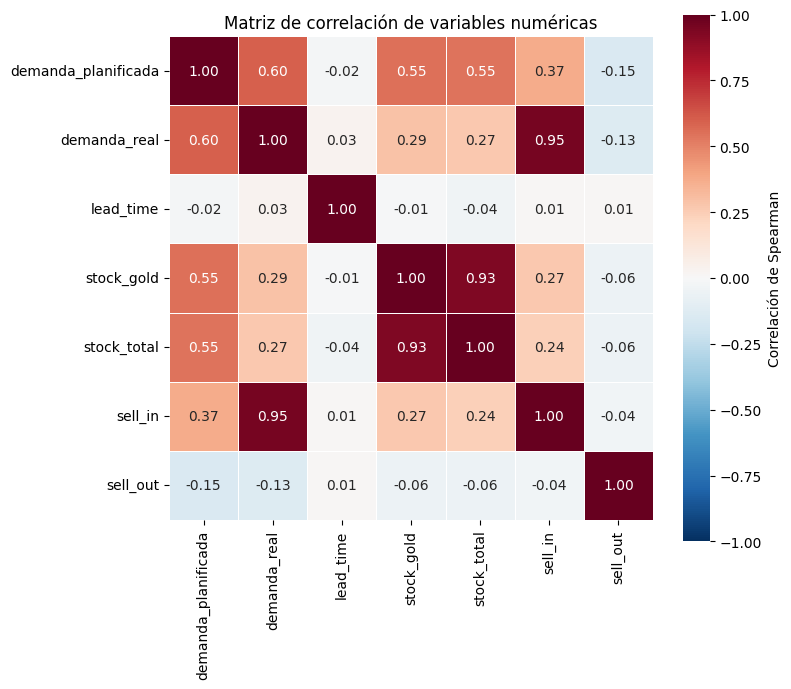

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(matriz_corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5,
            cbar_kws={'label': 'Correlación de Spearman'}, ax=ax)
ax.set_title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.savefig('figura2_correlacion_spearman.png', dpi=150)
plt.show()

# VISUALIZACIÓN DE VARIABLES

## Pareto ABC

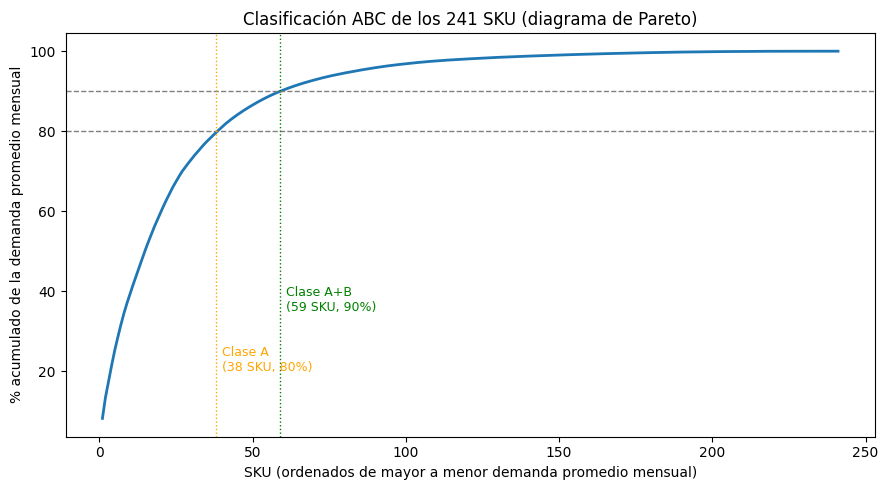

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(abc) + 1), abc['pct_acum'] * 100, linewidth=2)

n_a = (abc['clase'] == 'A').sum()
n_ab = abc['clase'].isin(['A', 'B']).sum()
ax.axhline(80, color='gray', linestyle='--', linewidth=1)
ax.axhline(90, color='gray', linestyle='--', linewidth=1)
ax.axvline(n_a, color='orange', linestyle=':', linewidth=1)
ax.axvline(n_ab, color='green', linestyle=':', linewidth=1)
ax.text(n_a + 2, 20, f'Clase A\n({n_a} SKU, 80%)', color='orange', fontsize=9)
ax.text(n_ab + 2, 35, f'Clase A+B\n({n_ab} SKU, 90%)', color='green', fontsize=9)

ax.set_xlabel('SKU (ordenados de mayor a menor demanda promedio mensual)')
ax.set_ylabel('% acumulado de la demanda promedio mensual')
ax.set_title(f'Clasificación ABC de los {len(abc)} SKU (diagrama de Pareto)')
plt.tight_layout()
plt.savefig('fig3_pareto_abc.png', dpi=150)
plt.show()

## demanda agregada (59 SKU) planificada vs. real

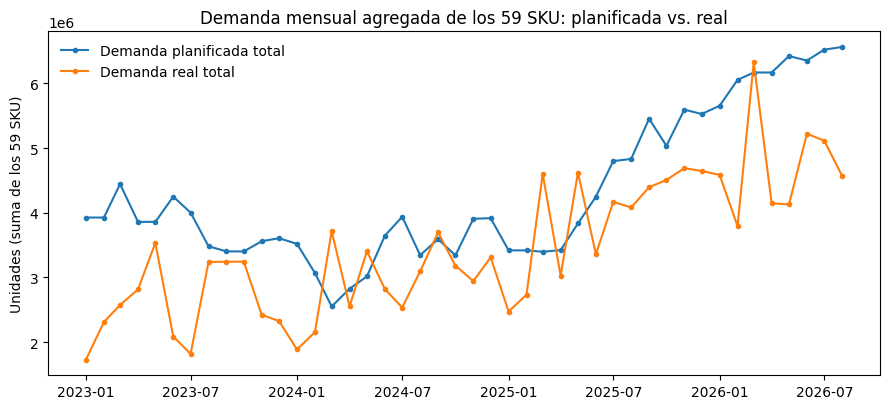

Meses con planificado > real: 38 de 44


In [ ]:
agg = consolidado.groupby('anio_mes').agg(
    demanda_planificada=('demanda_planificada', 'sum'),
    demanda_real=('demanda_real', 'sum')
).reset_index()
agg['mes_dt'] = agg['anio_mes'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(agg['mes_dt'], agg['demanda_planificada'], marker='o', markersize=3, label='Demanda planificada total')
ax.plot(agg['mes_dt'], agg['demanda_real'], marker='o', markersize=3, label='Demanda real total')
ax.set_title('Demanda mensual agregada de los 59 SKU: planificada vs. real')
ax.set_ylabel('Unidades (suma de los 59 SKU)')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('fig4_agregado.png', dpi=150)
plt.show()

# Meses en que la demanda planificada supera a la real (dato citado en el informe)
sobre = (agg['demanda_planificada'] > agg['demanda_real']).sum()
print(f"Meses con planificado > real: {sobre} de {len(agg)}")

## SKU de ejemplo (el de más meses con dato real)

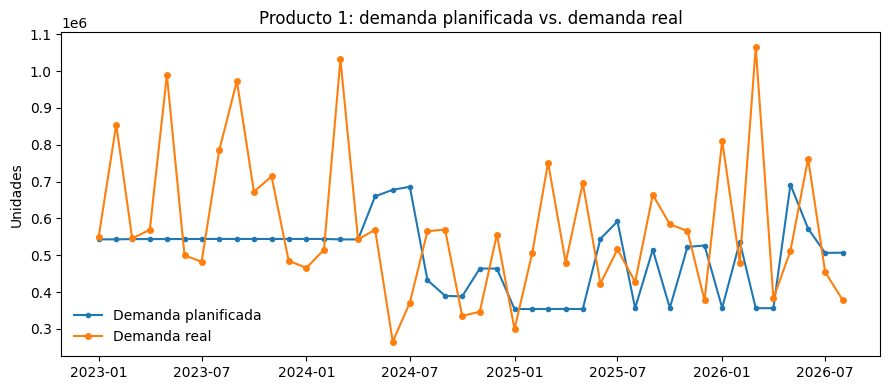

SKU usado: Producto 1


In [ ]:
sku_ejemplo = consolidado[consolidado.tiene_dato_real].groupby('sku').size().sort_values(ascending=False).index[0]
ej = consolidado[consolidado.sku == sku_ejemplo].sort_values('anio_mes').copy()
ej['mes_dt'] = ej['anio_mes'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ej['mes_dt'], ej['demanda_planificada'], marker='o', markersize=3, label='Demanda planificada')
ax.plot(ej['mes_dt'], ej['demanda_real'], marker='o', markersize=4, label='Demanda real')
ax.set_title(f'{sku_ejemplo}: demanda planificada vs. demanda real')
ax.set_ylabel('Unidades')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('fig5_sku_ejemplo.png', dpi=150)
plt.show()

print("SKU usado:", sku_ejemplo)

## boxplot de error por planta

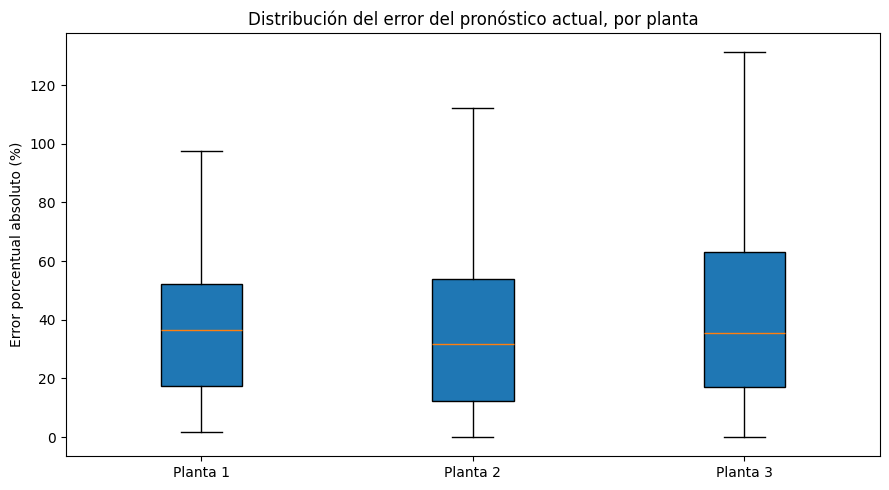

linea
Planta 1    36.360967
Planta 2    31.805556
Planta 3    35.529279
Name: ape, dtype: float64
linea
Planta 1    176
Planta 2    165
Planta 3    815
dtype: int64


In [ ]:
lineas = ['Planta 1', 'Planta 2', 'Planta 3']
data_por_planta = [comp_ok.loc[comp_ok.linea == l, 'ape'] * 100 for l in lineas]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data_por_planta, tick_labels=lineas, patch_artist=True, showfliers=False)
ax.set_ylabel('Error porcentual absoluto (%)')
ax.set_title('Distribución del error del pronóstico actual, por planta')
plt.tight_layout()
plt.savefig('fig6_boxplot_planta.png', dpi=150)
plt.show()

print(comp_ok.groupby('linea', observed=True)['ape'].median() * 100)
print(comp_ok.groupby('linea', observed=True).size())

MAPE mediana:  34.9%
WMAPE:         39.2%
MASE mediana:  0.69  (n=1156)


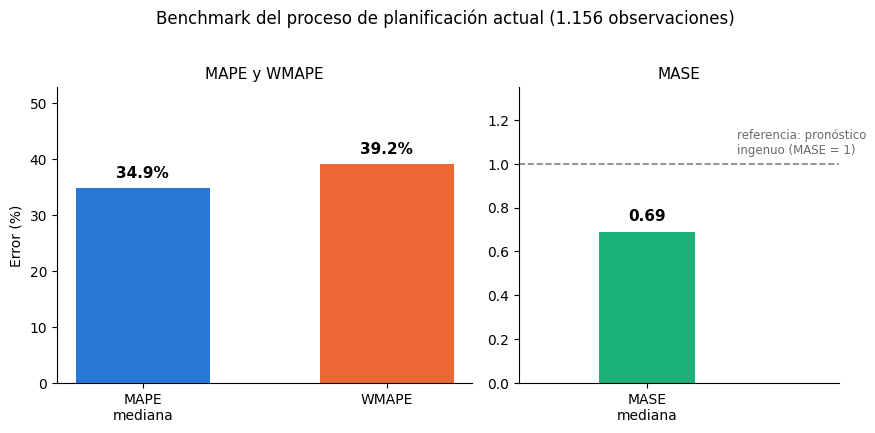

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1) Calcular MAPE mediana y WMAPE del proceso actual (sobre comp_ok)
# ============================================================
mape_mediana = comp_ok['ape'].median() * 100
wmape = comp_ok['error_abs'].sum() / comp_ok['demanda_real'].sum() * 100

# ============================================================
# 2) Calcular MASE mediana del proceso actual
#    (denominador: error medio del pronóstico ingenuo de cada SKU)
# ============================================================
real_series = consolidado.dropna(subset=['demanda_real']).sort_values(['sku', 'anio_mes']).copy()
naive_mae_por_sku = {}
for sku, g in real_series.groupby('sku'):
    g = g.sort_values('anio_mes')
    diffs = g['demanda_real'].diff().abs().dropna()
    if len(diffs) >= 1 and diffs.mean() > 0:
        naive_mae_por_sku[sku] = diffs.mean()

comp_mase = comp_ok.copy()
comp_mase['naive_mae'] = comp_mase['sku'].map(naive_mae_por_sku)
comp_mase = comp_mase.dropna(subset=['naive_mae'])
comp_mase = comp_mase[comp_mase['naive_mae'] > 0]
comp_mase['ase'] = comp_mase['error_abs'] / comp_mase['naive_mae']
mase_mediana = comp_mase['ase'].median()

print(f"MAPE mediana:  {mape_mediana:.1f}%")
print(f"WMAPE:         {wmape:.1f}%")
print(f"MASE mediana:  {mase_mediana:.2f}  (n={len(comp_mase)})")

# ============================================================
# 3) Graficar: dos paneles porque MAPE/WMAPE están en % y MASE es una razón
#    (mezclarlos en la misma escala sería engañoso)
# ============================================================
AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})

# Panel 1: MAPE mediana y WMAPE
labels1 = ['MAPE\nmediana', 'WMAPE']
vals1 = [mape_mediana, wmape]
bars1 = ax1.bar(labels1, vals1, color=[AZUL, NARANJA], width=0.55)
for b, v in zip(bars1, vals1):
    ax1.text(b.get_x() + b.get_width()/2, v + 1.2, f'{v:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_ylabel('Error (%)')
ax1.set_ylim(0, max(vals1) * 1.35)
ax1.set_title('MAPE y WMAPE', fontsize=11)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Panel 2: MASE mediana con línea de referencia en 1 (pronóstico ingenuo)
bar2 = ax2.bar(['MASE\nmediana'], [mase_mediana], color=AQUA, width=0.45)
ax2.axhline(1.0, color='gray', linestyle='--', linewidth=1.2)
ax2.text(0.42, 1.03, 'referencia: pronóstico\ningenuo (MASE = 1)', fontsize=8.5, color='dimgray', va='bottom')
ax2.text(0, mase_mediana + 0.04, f'{mase_mediana:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax2.set_ylim(0, max(1.35, mase_mediana * 1.3))
ax2.set_title('MASE', fontsize=11)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xlim(-0.6, 0.9)

fig.suptitle(f'Benchmark del proceso de planificación actual ({len(comp_ok):,} observaciones)'.replace(',', '.'), fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('figura7_benchmark_proceso_actual.png', dpi=150, bbox_inches='tight')
plt.show()

# MODELADO

## Paso 1: Preparación para el modelado

In [ ]:
# Se ordena la base por SKU y mes, y se separa el periodo de prueba
# (los últimos 3 meses con demanda real conocida) del periodo de entrenamiento.
np.random.seed(42)

base = base_corr.sort_values(['sku', 'anio_mes']).reset_index(drop=True)

MESES_TEST = pd.PeriodIndex(['2026-06', '2026-07', '2026-08'], freq='M')
test_mask = base['anio_mes'].isin(MESES_TEST) & base['demanda_real'].notna()
test_df = base[test_mask].copy()
train_df = base[~test_mask].copy()

print(f"Filas totales (sku-mes): {len(base):,}")
print(f"Filas con demanda_real conocida: {base['demanda_real'].notna().sum():,}")
print(f"Meses de prueba (fuera de muestra): {list(MESES_TEST)}")
print(f"Filas de prueba: {len(test_df):,} | Filas de entrenamiento: {len(train_df):,}")

Filas totales (sku-mes): 1,932
Filas con demanda_real conocida: 1,600
Meses de prueba (fuera de muestra): [Period('2026-06', 'M'), Period('2026-07', 'M'), Period('2026-08', 'M')]
Filas de prueba: 143 | Filas de entrenamiento: 1,789


In [ ]:
train_con_real = train_df.dropna(subset=['demanda_real'])

print(f"Periodo cubierto por train_df: {train_df['anio_mes'].min()} a {train_df['anio_mes'].max()}")
print(f"Filas totales en el periodo de entrenamiento: {len(train_df):,}")
print(f"De esas, con demanda_real conocida: {len(train_con_real):,}")
print(f"Rango de meses con demanda_real conocida: {train_con_real['anio_mes'].min()} a {train_con_real['anio_mes'].max()}")

Periodo cubierto por train_df: 2023-01 a 2026-08
Filas totales en el periodo de entrenamiento: 1,789
De esas, con demanda_real conocida: 1,457
Rango de meses con demanda_real conocida: 2023-01 a 2026-05


In [ ]:
# Verificación: de las 1,600 observaciones con demanda_real conocida,
# cuántas caen en el periodo de entrenamiento y cuántas en el de prueba.

conocidas = base[base['demanda_real'].notna()].copy()
en_train = conocidas[~conocidas['anio_mes'].isin(MESES_TEST)]
en_test = conocidas[conocidas['anio_mes'].isin(MESES_TEST)]

print(f"Total de filas con demanda_real conocida: {len(conocidas):,}")
print(f"  En periodo de entrenamiento (fuera de los 3 meses de prueba): {len(en_train):,}")
print(f"  En periodo de prueba (jun-ago 2026):                          {len(en_test):,}")
print(f"  Suma de verificación: {len(en_train):,} + {len(en_test):,} = {len(en_train) + len(en_test):,}")

print(f"\nRango de meses de 'en_train': {en_train['anio_mes'].min()} a {en_train['anio_mes'].max()}")

# Segunda verificación: contra los train_df / test_df que ya construiste en la celda del split
print(f"\n--- Cruce contra train_df y test_df ya construidos ---")
print(f"train_df filas totales: {len(train_df):,} | de esas, con demanda_real conocida: {train_df['demanda_real'].notna().sum():,}")
print(f"test_df filas totales:  {len(test_df):,} | de esas, con demanda_real conocida: {test_df['demanda_real'].notna().sum():,}")

Total de filas con demanda_real conocida: 1,600
  En periodo de entrenamiento (fuera de los 3 meses de prueba): 1,457
  En periodo de prueba (jun-ago 2026):                          143
  Suma de verificación: 1,457 + 143 = 1,600

Rango de meses de 'en_train': 2023-01 a 2026-05

--- Cruce contra train_df y test_df ya construidos ---
train_df filas totales: 1,789 | de esas, con demanda_real conocida: 1,457
test_df filas totales:  143 | de esas, con demanda_real conocida: 143


## Función de métricas de evaluación

In [ ]:
# Función de métricas (definiciones de la Tabla 7 del informe: MAE, RMSE, MAPE mediana,
# WMAPE y MASE). En esta etapa el MASE se calcula como la mediana del error absoluto del
# modelo dividida para la mediana del error del pronóstico ingenuo; el mismo denominador
# se usa para los cuatro métodos, por lo que la comparación entre ellos es directa.
def metricas(y_true, y_pred, y_naive_err):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    ape = np.abs(err) / np.where(y_true == 0, np.nan, y_true)
    mape = np.nanmedian(ape) * 100
    wmape = np.sum(np.abs(err)) / np.sum(np.abs(y_true)) * 100
    mase = np.median(np.abs(err)) / np.median(y_naive_err) if np.median(y_naive_err) > 0 else np.nan
    return {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'MAPE_mediana_%': round(mape, 1),
            'WMAPE_%': round(wmape, 1), 'MASE_mediana': round(mase, 2)}

# Error del pronóstico ingenuo (repetir el mes anterior), por SKU. Es el denominador de MASE.
base_naive = base.dropna(subset=['demanda_real']).sort_values(['sku', 'anio_mes']).copy()
base_naive['naive_pred'] = base_naive.groupby('sku')['demanda_real'].shift(1)
naive_err_full = (base_naive['naive_pred'] - base_naive['demanda_real']).abs().dropna().values

In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(42)

skus = base['sku'].unique().tolist()
seqs = [base[base['sku'] == sku].sort_values('anio_mes').reset_index(drop=True) for sku in skus]

mean_real = train_df['demanda_real'].mean()
std_real = train_df['demanda_real'].std() + 1e-6
mean_planif = train_df['demanda_planificada'].mean()
std_planif = train_df['demanda_planificada'].std() + 1e-6

max_len = max(len(g) for g in seqs)
n = len(seqs)
X = np.zeros((n, max_len, 2), dtype=np.float32)
Y = np.zeros((n, max_len), dtype=np.float32)
mask_loss = np.zeros((n, max_len), dtype=np.float32)
mask_test = np.zeros((n, max_len), dtype=np.float32)
lengths = np.zeros(n, dtype=np.int64)
real_vals = np.zeros((n, max_len), dtype=np.float32)

for i, g in enumerate(seqs):
    L = len(g)
    lengths[i] = L
    real = g['demanda_real'].values.astype(float)
    real_filled = pd.Series(real).ffill().bfill().fillna(mean_real).values
    planif = (g['demanda_planificada'].values.astype(float) - mean_planif) / std_planif
    lag_real = np.concatenate([[mean_real], real_filled[:-1]])
    lag_real_std = (lag_real - mean_real) / std_real
    X[i, :L, 0] = lag_real_std
    X[i, :L, 1] = planif
    Y[i, :L] = (real_filled - mean_real) / std_real
    real_vals[i, :L] = real
    es_test_mes = g['anio_mes'].isin(MESES_TEST).values
    tiene_real = ~np.isnan(real)
    mask_loss[i, :L] = (tiene_real & ~es_test_mes).astype(np.float32)
    mask_test[i, :L] = (tiene_real & es_test_mes).astype(np.float32)

X_t = torch.tensor(X)
Y_t = torch.tensor(Y)
mask_loss_t = torch.tensor(mask_loss)

print(f"Secuencias (SKU): {n} | Largo máximo: {max_len} meses")

Secuencias (SKU): 59 | Largo máximo: 44 meses


In [ ]:
import numpy as np


# --- Paso 1: los estadísticos reales usados para la normalización ---
print("Estadísticos de normalización (calculados SOLO con train_df):")
print(f"  mean_real   = {mean_real:,.2f}   std_real   = {std_real:,.2f}")
print(f"  mean_planif = {mean_planif:,.2f}   std_planif = {std_planif:,.2f}")

# --- Paso 3: cuántos SKU necesitaron padding ---
print(f"\nLargo de las 59 secuencias: mínimo {lengths.min()}, máximo {lengths.max()}, "
      f"promedio {lengths.mean():.1f} meses")
print(f"SKU con 44 meses completos (sin padding): {(lengths == 44).sum()} de {len(lengths)}")
print(f"SKU con menos de 44 meses (requirieron padding): {(lengths < 44).sum()} de {len(lengths)}")

# --- Ejemplo concreto con un SKU de longitud intermedia ---
idx = np.argsort(lengths)[len(lengths)//2]
sku_ejemplo = skus[idx]
L = lengths[idx]
print(f"\n--- Ejemplo: SKU {sku_ejemplo} (longitud real = {L} de 44 meses) ---")
print(f"demanda_real, primeros 5 meses:               {real_vals[idx, :5].round(1)}")
print(f"Entrada X[...,0] (demanda rezagada normalizada), primeros 5 meses: {X[idx, :5, 0].round(3)}")
print(f"Entrada X[...,1] (demanda planificada normalizada), primeros 5 meses: {X[idx, :5, 1].round(3)}")
print(f"\nAlrededor del límite entre datos reales y relleno (posiciones {L-2} a {L+2}):")
print(f"  mask_loss (entrenamiento): {mask_loss[idx, L-2:L+3]}")
print(f"  mask_test (prueba):        {mask_test[idx, L-2:L+3]}")
print(f"  X en esas posiciones (debe volverse 0 después de L={L}, eso es el padding):")
print(X[idx, L-2:L+3, :])

Estadísticos de normalización (calculados SOLO con train_df):
  mean_real   = 92,834.02   std_real   = 119,995.98
  mean_planif = 95,382.68   std_planif = 102,130.52

Largo de las 59 secuencias: mínimo 7, máximo 44, promedio 32.7 meses
SKU con 44 meses completos (sin padding): 28 de 59
SKU con menos de 44 meses (requirieron padding): 31 de 59

--- Ejemplo: SKU Producto 23 (longitud real = 40 de 44 meses) ---
demanda_real, primeros 5 meses:               [40000. 20010.   220.   400. 20000.]
Entrada X[...,0] (demanda rezagada normalizada), primeros 5 meses: [ 0.    -0.44  -0.607 -0.772 -0.77 ]
Entrada X[...,1] (demanda planificada normalizada), primeros 5 meses: [2.143 2.143 2.143 2.2   2.2  ]

Alrededor del límite entre datos reales y relleno (posiciones 38 a 42):
  mask_loss (entrenamiento): [0. 0. 0. 0. 0.]
  mask_test (prueba):        [1. 1. 0. 0. 0.]
  X en esas posiciones (debe volverse 0 después de L=40, eso es el padding):
[[-0.6069289 -0.7381014]
 [-0.690215  -0.7381014]
 [ 0.  

# Paso 2: Línea base (proceso de planificación actual)

In [ ]:
# Se evalúa demanda_planificada contra demanda_real en el MISMO periodo de prueba
# que se usará para los 3 modelos, para que la comparación sea justa.
baseline_metrics = metricas(test_df['demanda_real'], test_df['demanda_planificada'], naive_err_full)
print("Línea base (proceso de planificación actual) - periodo de prueba:")
baseline_metrics

Línea base (proceso de planificación actual) - periodo de prueba:


{'MAE': np.float64(53096.53),
 'RMSE': np.float64(96749.21),
 'MAPE_mediana_%': np.float64(36.6),
 'WMAPE_%': np.float64(50.9),
 'MASE_mediana': np.float64(1.1)}

# Paso 3: Modelo LSTM

In [ ]:
class LSTMDemanda(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=2, hidden_size=hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return self.out(h).squeeze(-1)

lstm_model = LSTMDemanda(hidden=16)
opt = torch.optim.Adam(lstm_model.parameters(), lr=0.01)
loss_fn = nn.MSELoss(reduction='none')

for epoch in range(200):
    lstm_model.train()
    opt.zero_grad()
    pred = lstm_model(X_t)
    loss_raw = loss_fn(pred, Y_t)
    loss = (loss_raw * mask_loss_t).sum() / mask_loss_t.sum()
    loss.backward()
    opt.step()
    if (epoch + 1) % 50 == 0:
        print(f"  epoch {epoch+1:3d}  train_loss={loss.item():.4f}")

  epoch  50  train_loss=0.2649
  epoch 100  train_loss=0.2438
  epoch 150  train_loss=0.2289
  epoch 200  train_loss=0.2130


In [ ]:
lstm_model.eval()
with torch.no_grad():
    pred_all = lstm_model(X_t).numpy()
pred_real_scale = pred_all * std_real + mean_real

lstm_true, lstm_pred = [], []
for i in range(n):
    idx = np.where(mask_test[i, :lengths[i]] == 1)[0]
    for j in idx:
        lstm_true.append(real_vals[i, j])
        lstm_pred.append(pred_real_scale[i, j])
lstm_true = np.array(lstm_true)
lstm_pred = np.array(lstm_pred)

lstm_metrics = metricas(lstm_true, lstm_pred, naive_err_full)
print("LSTM - periodo de prueba:")
lstm_metrics

LSTM - periodo de prueba:


{'MAE': np.float64(35864.92),
 'RMSE': np.float64(61340.69),
 'MAPE_mediana_%': np.float64(30.7),
 'WMAPE_%': np.float64(34.4),
 'MASE_mediana': np.float64(0.75)}

# Paso 4: Modelo XGBoost

## Preparación de variables

In [ ]:
from xgboost import XGBRegressor

feat_num = ['demanda_planificada', 'lead_time', 'stock_total']
feat_cat = ['sku', 'linea', 'clase_abc']

xgb_train = train_df.dropna(subset=['demanda_real']).copy()
for c in feat_cat:
    xgb_train[c] = xgb_train[c].astype('category')
    test_df[c] = pd.Categorical(test_df[c], categories=xgb_train[c].cat.categories)

X_train = xgb_train[feat_num + feat_cat]
y_train = xgb_train['demanda_real']
X_test = test_df[feat_num + feat_cat]
y_test = test_df['demanda_real']

print(f"Filas de entrenamiento (con demanda_real conocida): {len(X_train):,}")
print(f"Variables numéricas: {feat_num}")
print(f"Variables categóricas: {feat_cat}")

Filas de entrenamiento (con demanda_real conocida): 1,457
Variables numéricas: ['demanda_planificada', 'lead_time', 'stock_total']
Variables categóricas: ['sku', 'linea', 'clase_abc']


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd

orden = xgb_train['anio_mes'].argsort().values
X_train_ord = X_train.iloc[orden].reset_index(drop=True)
y_train_ord = y_train.iloc[orden].reset_index(drop=True)

tscv = TimeSeriesSplit(n_splits=4)
n_estimators_range = [10, 25, 50, 100, 150, 200, 300, 500, 800]

resultados_ne = []
for n in n_estimators_range:
    maes_fold = []
    for train_idx, val_idx in tscv.split(X_train_ord):
        modelo = XGBRegressor(
            n_estimators=n, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            enable_categorical=True, tree_method='hist', random_state=42,
        )
        modelo.fit(X_train_ord.iloc[train_idx], y_train_ord.iloc[train_idx])
        pred_val = modelo.predict(X_train_ord.iloc[val_idx])
        mae_fold = np.abs(pred_val - y_train_ord.iloc[val_idx]).mean()
        maes_fold.append(mae_fold)
    resultados_ne.append({'n_estimators': n, 'MAE_val_promedio': round(np.mean(maes_fold), 2)})

df_ne = pd.DataFrame(resultados_ne)
print(df_ne)

   n_estimators  MAE_val_promedio
0            10          53495.49
1            25          42047.56
2            50          37546.63
3           100          37364.74
4           150          37601.56
5           200          37886.70
6           300          38189.91
7           500          38776.22
8           800          39490.51


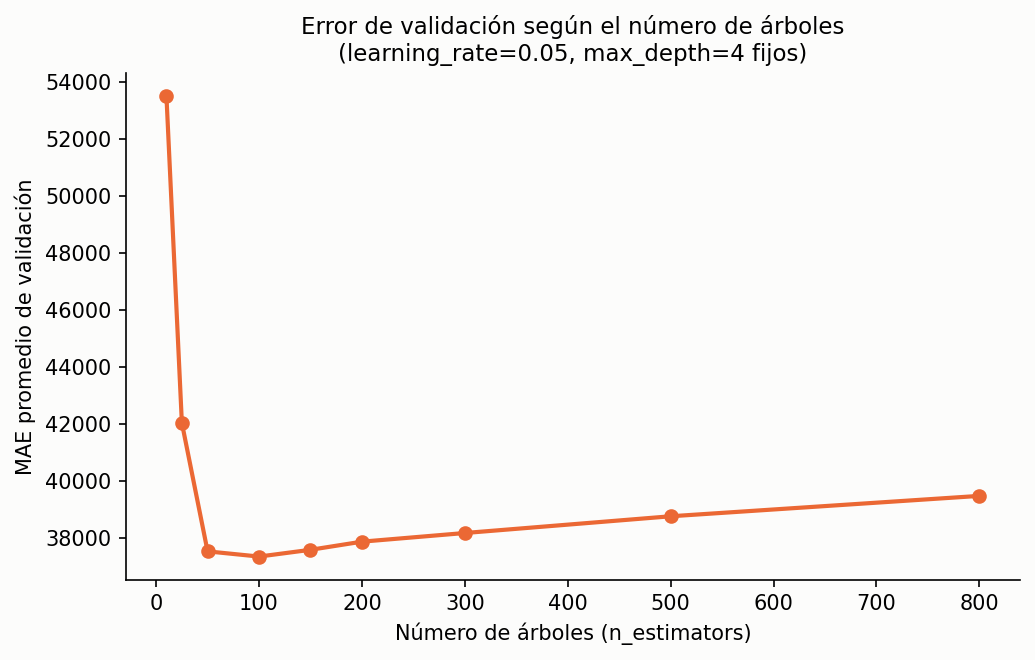

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
fig.patch.set_facecolor('#fcfcfb')
ax.plot(df_ne['n_estimators'], df_ne['MAE_val_promedio'], color='#eb6834', marker='o', linewidth=2)
ax.set_xlabel('Número de árboles (n_estimators)')
ax.set_ylabel('MAE promedio de validación')
ax.set_title('Error de validación según el número de árboles\n(learning_rate=0.05, max_depth=4 fijos)', fontsize=11)
ax.set_facecolor('#fcfcfb')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figura10_curva_n_estimators.png', dpi=150, facecolor='#fcfcfb', bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

orden = xgb_train['anio_mes'].argsort().values
X_train_ord = X_train.iloc[orden].reset_index(drop=True)
y_train_ord = y_train.iloc[orden].reset_index(drop=True)

param_grid = {
    'n_estimators': [100, 150, 300, 500],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5],
}

tscv = TimeSeriesSplit(n_splits=4)

base_model = XGBRegressor(
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    enable_categorical=True, tree_method='hist', random_state=42,
)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    n_jobs=-1,
)
grid_search.fit(X_train_ord, y_train_ord)

print("Mejor combinación encontrada por GridSearchCV:")
print(grid_search.best_params_)
print(f"MAE promedio de validación (CV, 4 particiones temporales): {-grid_search.best_score_:,.2f}")

Mejor combinación encontrada por GridSearchCV:
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 150}
MAE promedio de validación (CV, 4 particiones temporales): 37,059.45


In [ ]:
import pandas as pd

resultados_grid = pd.DataFrame(grid_search.cv_results_)
resultados_grid['MAE_val_promedio'] = -resultados_grid['mean_test_score']
resultados_grid = resultados_grid[[
    'param_n_estimators', 'param_learning_rate', 'param_max_depth',
    'MAE_val_promedio', 'rank_test_score'
]].sort_values('rank_test_score')

print(resultados_grid.to_string(index=False))

 param_n_estimators  param_learning_rate  param_max_depth  MAE_val_promedio  rank_test_score
                150                 0.03                3      37059.454108                1
                100                 0.05                3      37152.652552                2
                150                 0.03                4      37167.851101                3
                100                 0.03                4      37239.804920                4
                300                 0.03                3      37301.999231                5
                150                 0.05                3      37307.939356                6
                100                 0.05                4      37364.737132                7
                150                 0.03                5      37528.186148                8
                100                 0.03                5      37568.027978                9
                150                 0.05                4      37601.5

## Entrenamiento y evaluación de XGBoost (configuración final)

In [ ]:
xgb_model = XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    enable_categorical=True, tree_method='hist', random_state=42,
)
xgb_model.fit(X_train, y_train)
xgb_pred_test = xgb_model.predict(X_test)

xgb_metrics = metricas(y_test, xgb_pred_test, naive_err_full)
print("XGBoost - periodo de prueba:")
xgb_metrics

XGBoost - periodo de prueba:


{'MAE': np.float64(37194.5),
 'RMSE': np.float64(62229.87),
 'MAPE_mediana_%': np.float64(33.8),
 'WMAPE_%': np.float64(35.7),
 'MASE_mediana': np.float64(0.99)}

# Paso 5: Modelo híbrido (LSTM + XGBoost)

In [ ]:
lstm_rows = []
for i, g in enumerate(seqs):
    idx = np.where(mask_test[i, :lengths[i]] == 1)[0]
    for j in idx:
        lstm_rows.append({'sku': g.loc[j, 'sku'], 'anio_mes': g.loc[j, 'anio_mes'], 'lstm_pred': pred_real_scale[i, j]})
lstm_df = pd.DataFrame(lstm_rows)

comparacion_test = test_df[['sku', 'anio_mes', 'demanda_real']].copy()
comparacion_test['xgb_pred'] = xgb_pred_test
comparacion_test = comparacion_test.merge(lstm_df, on=['sku', 'anio_mes'], how='inner')

W1_XGB, W2_LSTM = 0.65, 0.35
comparacion_test['hibrido_pred'] = W1_XGB * comparacion_test['xgb_pred'] + W2_LSTM * comparacion_test['lstm_pred']

hibrido_metrics = metricas(comparacion_test['demanda_real'], comparacion_test['hibrido_pred'], naive_err_full)
print(f"Híbrido (w1={W1_XGB}, w2={W2_LSTM}) - periodo de prueba:")
hibrido_metrics

Híbrido (w1=0.65, w2=0.35) - periodo de prueba:


{'MAE': np.float64(35974.49),
 'RMSE': np.float64(60429.04),
 'MAPE_mediana_%': np.float64(34.0),
 'WMAPE_%': np.float64(34.5),
 'MASE_mediana': np.float64(0.88)}

## Búsqueda del peso óptimo w1 (exploratoria)

In [ ]:
mejor = None
for w1 in np.arange(0, 1.01, 0.05):
    pred_w = w1 * comparacion_test['xgb_pred'] + (1 - w1) * comparacion_test['lstm_pred']
    err = np.abs(pred_w - comparacion_test['demanda_real'])
    wmape_w = err.sum() / comparacion_test['demanda_real'].abs().sum() * 100
    if mejor is None or wmape_w < mejor[1]:
        mejor = (round(w1, 2), wmape_w)
print(f"Mejor w1 por grid search: w1={mejor[0]}, w2={round(1-mejor[0],2)} -> WMAPE={mejor[1]:.1f}%")

Mejor w1 por grid search: w1=0.25, w2=0.75 -> WMAPE=33.9%


# Comparación de los modelos (Tabla 13)

In [ ]:
resumen = pd.DataFrame({
    'Proceso actual': baseline_metrics,
    'LSTM': lstm_metrics,
    'XGBoost': xgb_metrics,
    f'Híbrido (w1={W1_XGB})': hibrido_metrics,
}).T
resumen

,MAE,RMSE,MAPE_mediana_%,WMAPE_%,MASE_mediana
Proceso actual,53096.53,96749.21,36.6,50.9,1.10
LSTM,35864.92,61340.69,30.7,34.4,0.75
XGBoost,37194.50,62229.87,33.8,35.7,0.99
Híbrido (w1=0.65),35974.49,60429.04,34.0,34.5,0.88


  epoch  50  train_loss=0.2649
  epoch 100  train_loss=0.2438
  epoch 150  train_loss=0.2289
  epoch 200  train_loss=0.2130

Pérdida en época 50:  0.2649
Pérdida en época 200: 0.2130


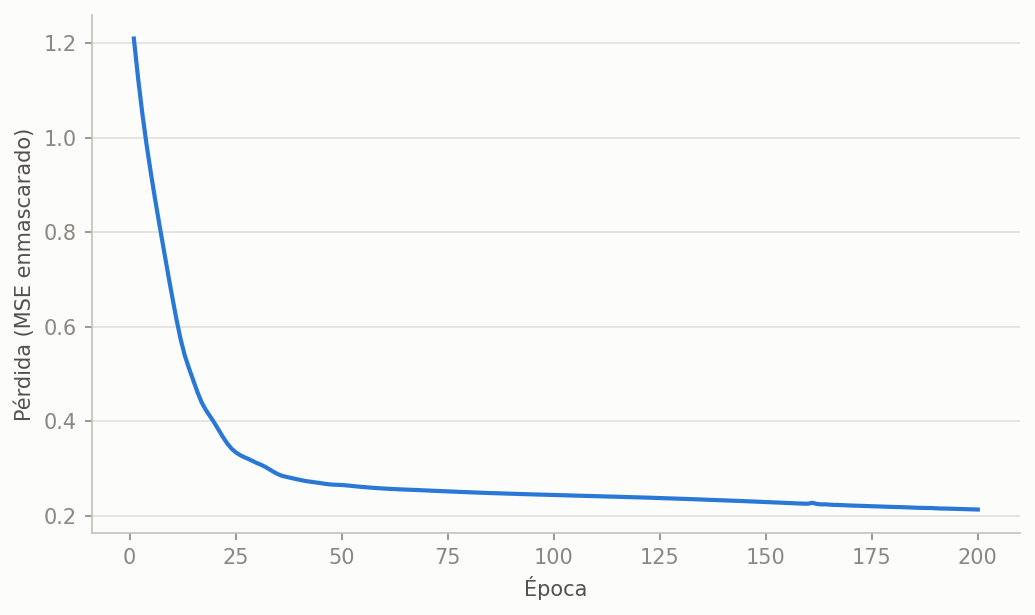

In [ ]:
import matplotlib.pyplot as plt

# Reentrenamiento con la misma semilla, guardando el historial de pérdida
torch.manual_seed(42)
lstm_model = LSTMDemanda(hidden=16)
opt = torch.optim.Adam(lstm_model.parameters(), lr=0.01)
loss_fn = nn.MSELoss(reduction='none')

historial_loss = []
for epoch in range(200):
    lstm_model.train()
    opt.zero_grad()
    pred = lstm_model(X_t)
    loss_raw = loss_fn(pred, Y_t)
    loss = (loss_raw * mask_loss_t).sum() / mask_loss_t.sum()
    loss.backward()
    opt.step()
    historial_loss.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"  epoch {epoch+1:3d}  train_loss={loss.item():.4f}")

print(f"\nPérdida en época 50:  {historial_loss[49]:.4f}")
print(f"Pérdida en época 200: {historial_loss[199]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2), dpi=150)
ax.plot(range(1, 201), historial_loss, color='#2a78d6', linewidth=2)
ax.set_xlabel('Época', color='#52514e')
ax.set_ylabel('Pérdida (MSE enmascarado)', color='#52514e')
ax.set_facecolor('#fcfcfb')
fig.patch.set_facecolor('#fcfcfb')
ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#c3c2b7')
ax.tick_params(colors='#898781')
plt.tight_layout()
plt.savefig('figura12_curva_perdida_lstm.png', dpi=150, facecolor='#fcfcfb')
plt.show()

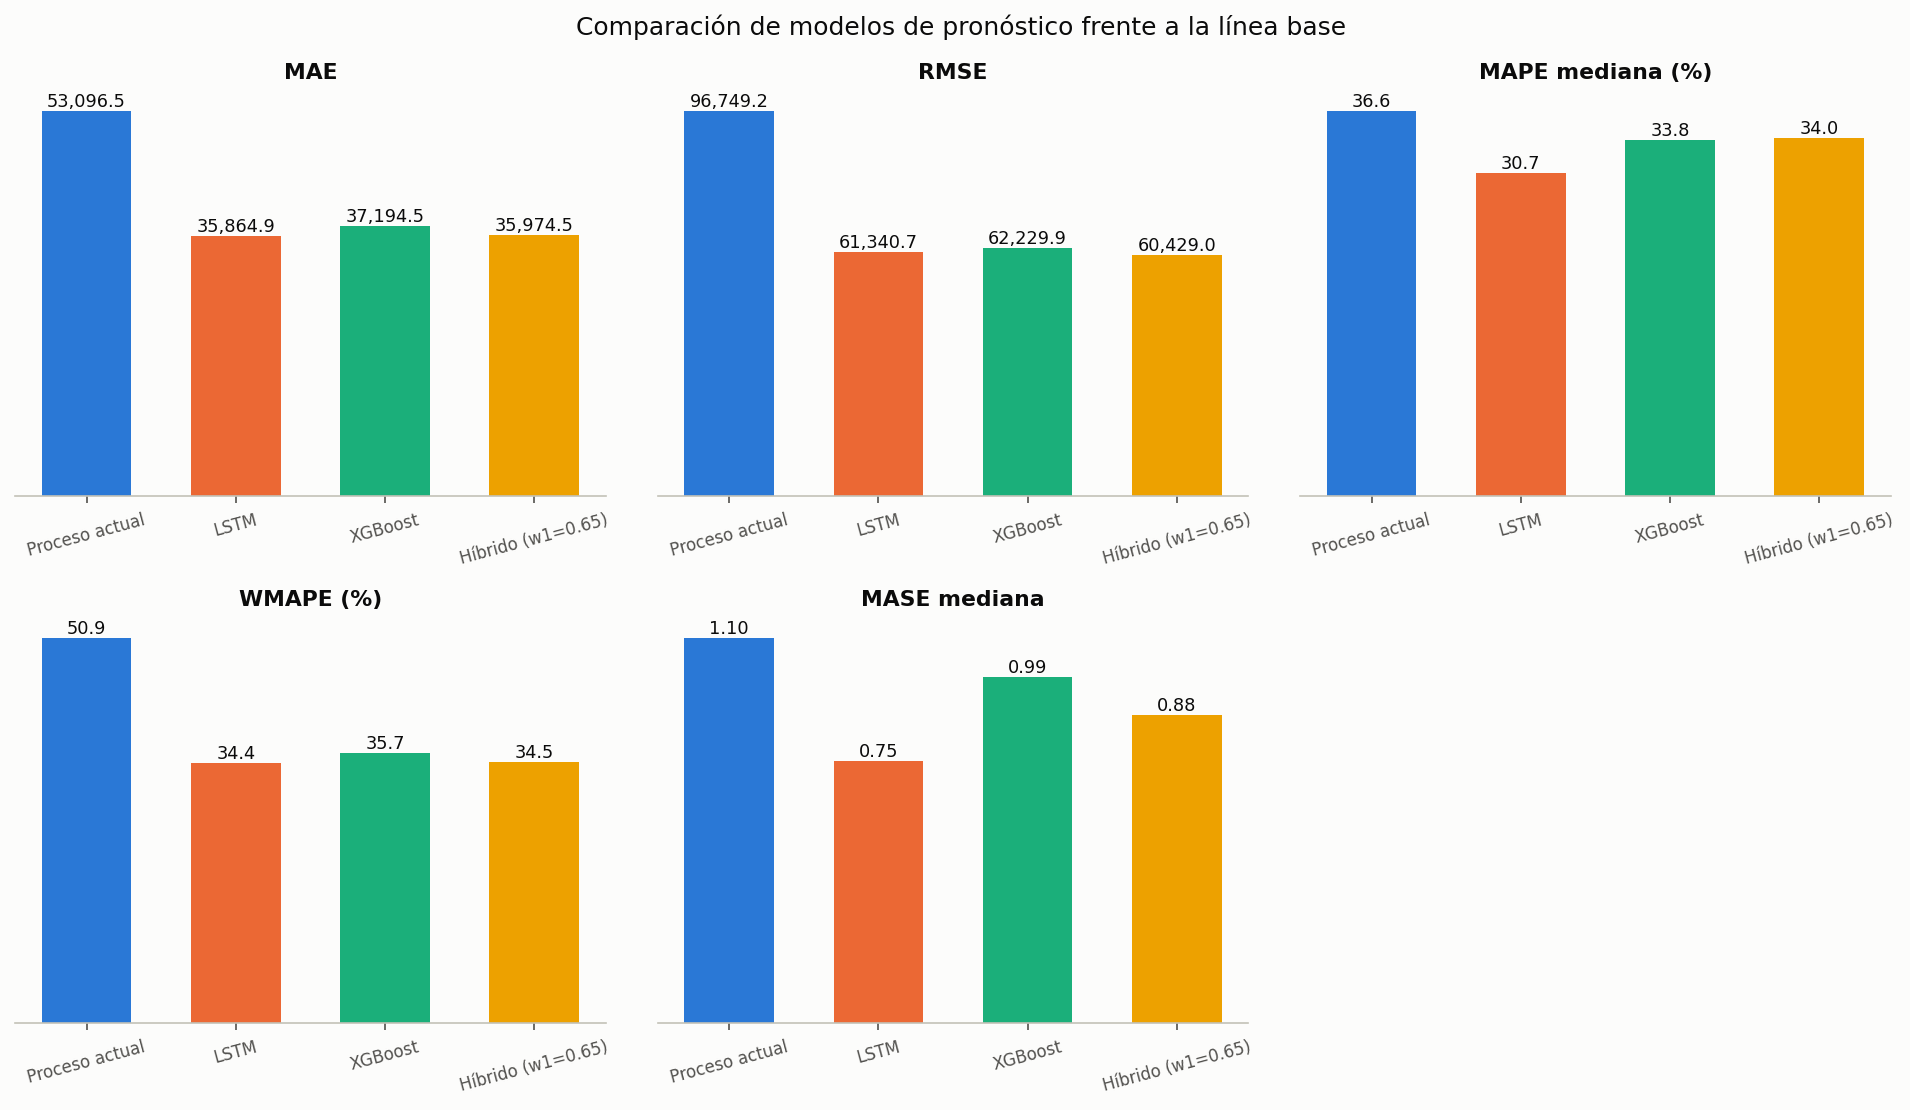

In [ ]:
import matplotlib.pyplot as plt

modelos = resumen.index.tolist()
colores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']  # Proceso actual, LSTM, XGBoost, Híbrido

metricas_plot = [
    ('MAE', 'MAE'),
    ('RMSE', 'RMSE'),
    ('MAPE_mediana_%', 'MAPE mediana (%)'),
    ('WMAPE_%', 'WMAPE (%)'),
    ('MASE_mediana', 'MASE mediana'),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), dpi=150)
fig.patch.set_facecolor('#fcfcfb')
axes = axes.flatten()

for ax, (col, label) in zip(axes, metricas_plot):
    valores = resumen[col].values
    bars = ax.bar(modelos, valores, color=colores, width=0.6)
    for bar, v in zip(bars, valores):
        etiqueta = f'{v:,.1f}' if v >= 10 else f'{v:.2f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), etiqueta,
                 ha='center', va='bottom', fontsize=8.5, color='#0b0b0b')
    ax.set_title(label, fontsize=10.5, color='#0b0b0b', fontweight='bold')
    ax.set_facecolor('#fcfcfb')
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.get_yaxis().set_visible(False)
    ax.tick_params(axis='x', labelrotation=15, labelsize=8, colors='#52514e')

axes[-1].axis('off')  # 5 métricas en una grilla de 6, el último panel queda vacío

fig.suptitle('Comparación de modelos de pronóstico frente a la línea base', fontsize=12, color='#0b0b0b')
plt.tight_layout()
plt.savefig('figura13_comparacion_modelos.png', dpi=150, facecolor='#fcfcfb', bbox_inches='tight')
plt.show()

# Paso 6: Evaluación del modelo LSTM por planta y por producto

In [ ]:
# Evaluación del modelo LSTM (el de mejor desempeño) por planta y por producto — Objetivo 5
seg_info = test_df[['sku', 'anio_mes', 'linea', 'clase_abc']].drop_duplicates()
comp_seg = comparacion_test.merge(seg_info, on=['sku', 'anio_mes'], how='left')

def metricas_seg(df, pred_col):
    err = df[pred_col] - df['demanda_real']
    mae = err.abs().mean()
    wmape = err.abs().sum() / df['demanda_real'].abs().sum() * 100
    return pd.Series({'n': len(df), 'MAE': round(mae, 2), 'WMAPE_%': round(wmape, 1)})

print("=== LSTM por planta ===")
print(comp_seg.groupby('linea').apply(lambda g: metricas_seg(g, 'lstm_pred')))

print("\n=== LSTM por clase ABC ===")
print(comp_seg.groupby('clase_abc').apply(lambda g: metricas_seg(g, 'lstm_pred')))

print("\n=== LSTM por SKU: 5 mejores y 5 peores por WMAPE ===")
por_sku = comp_seg.groupby('sku').apply(lambda g: metricas_seg(g, 'lstm_pred')).sort_values('WMAPE_%')
print("Mejores 5:")
print(por_sku.head(5))
print("\nPeores 5:")
print(por_sku.tail(5))

=== LSTM por planta ===
              n       MAE  WMAPE_%
linea                             
Planta 1   18.0  20947.68     32.3
Planta 2   21.0  15248.51     29.1
Planta 3  104.0  42609.68     35.1

=== LSTM por clase ABC ===
              n       MAE  WMAPE_%
clase_abc                         
A          83.0  50922.16     34.3
B          60.0  15035.73     34.9
C           0.0       NaN      NaN

=== LSTM por SKU: 5 mejores y 5 peores por WMAPE ===
Mejores 5:
               n       MAE  WMAPE_%
sku                                
Producto 50  3.0    222.56      0.6
Producto 46  3.0   4116.66      5.5
Producto 11  3.0  11843.11      7.9
Producto 28  3.0   3305.16      8.9
Producto 55  3.0   8756.01     10.5

Peores 5:
               n       MAE   WMAPE_%
sku                                 
Producto 49  3.0  11539.61      81.8
Producto 58  2.0  12431.75      82.9
Producto 23  3.0  10355.12     102.8
Producto 41  2.0   3826.47   47830.9
Producto 2   3.0   9916.64  228845.5


/tmp/ipykernel_1434/852134713.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(comp_seg.groupby('linea').apply(lambda g: metricas_seg(g, 'lstm_pred')))
/tmp/ipykernel_1434/852134713.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(comp_seg.groupby('linea').apply(lambda g: metricas_seg(g, 'lstm_pred')))
/tmp/ipykernel_1434/852134713.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain curr

In [ ]:
cols = ['sku', 'anio_mes', 'demanda_real', 'lstm_pred']
for sku in ['Producto 41', 'Producto 2', 'Producto 23']:
    print(f"--- {sku} ---")
    print(comparacion_test.loc[comparacion_test['sku'] == sku, cols].to_string(index=False))
    print()

--- Producto 41 ---
        sku anio_mes  demanda_real   lstm_pred
Producto 41  2026-06           5.0 3837.415417
Producto 41  2026-07          11.0 3831.532604

--- Producto 2 ---
       sku anio_mes  demanda_real    lstm_pred
Producto 2  2026-06           4.0  5661.368542
Producto 2  2026-07           4.0 21059.259167
Producto 2  2026-08           5.0  3042.290417

--- Producto 23 ---
        sku anio_mes  demanda_real    lstm_pred
Producto 23  2026-06       20005.0 17155.118542
Producto 23  2026-07       10011.0 20688.243542
Producto 23  2026-08         200.0 17738.227917



SKU usado (el mismo de la Figura 5): Producto 1
anio_mes  demanda_real     xgb_pred     lstm_pred  hibrido_pred
 2026-06      762700.0 416619.34375 599376.493542 480584.335240
 2026-07      454500.0 531661.25000 551251.837292 538517.955552
 2026-08      378100.0 450177.50000 585149.087292 497417.555552


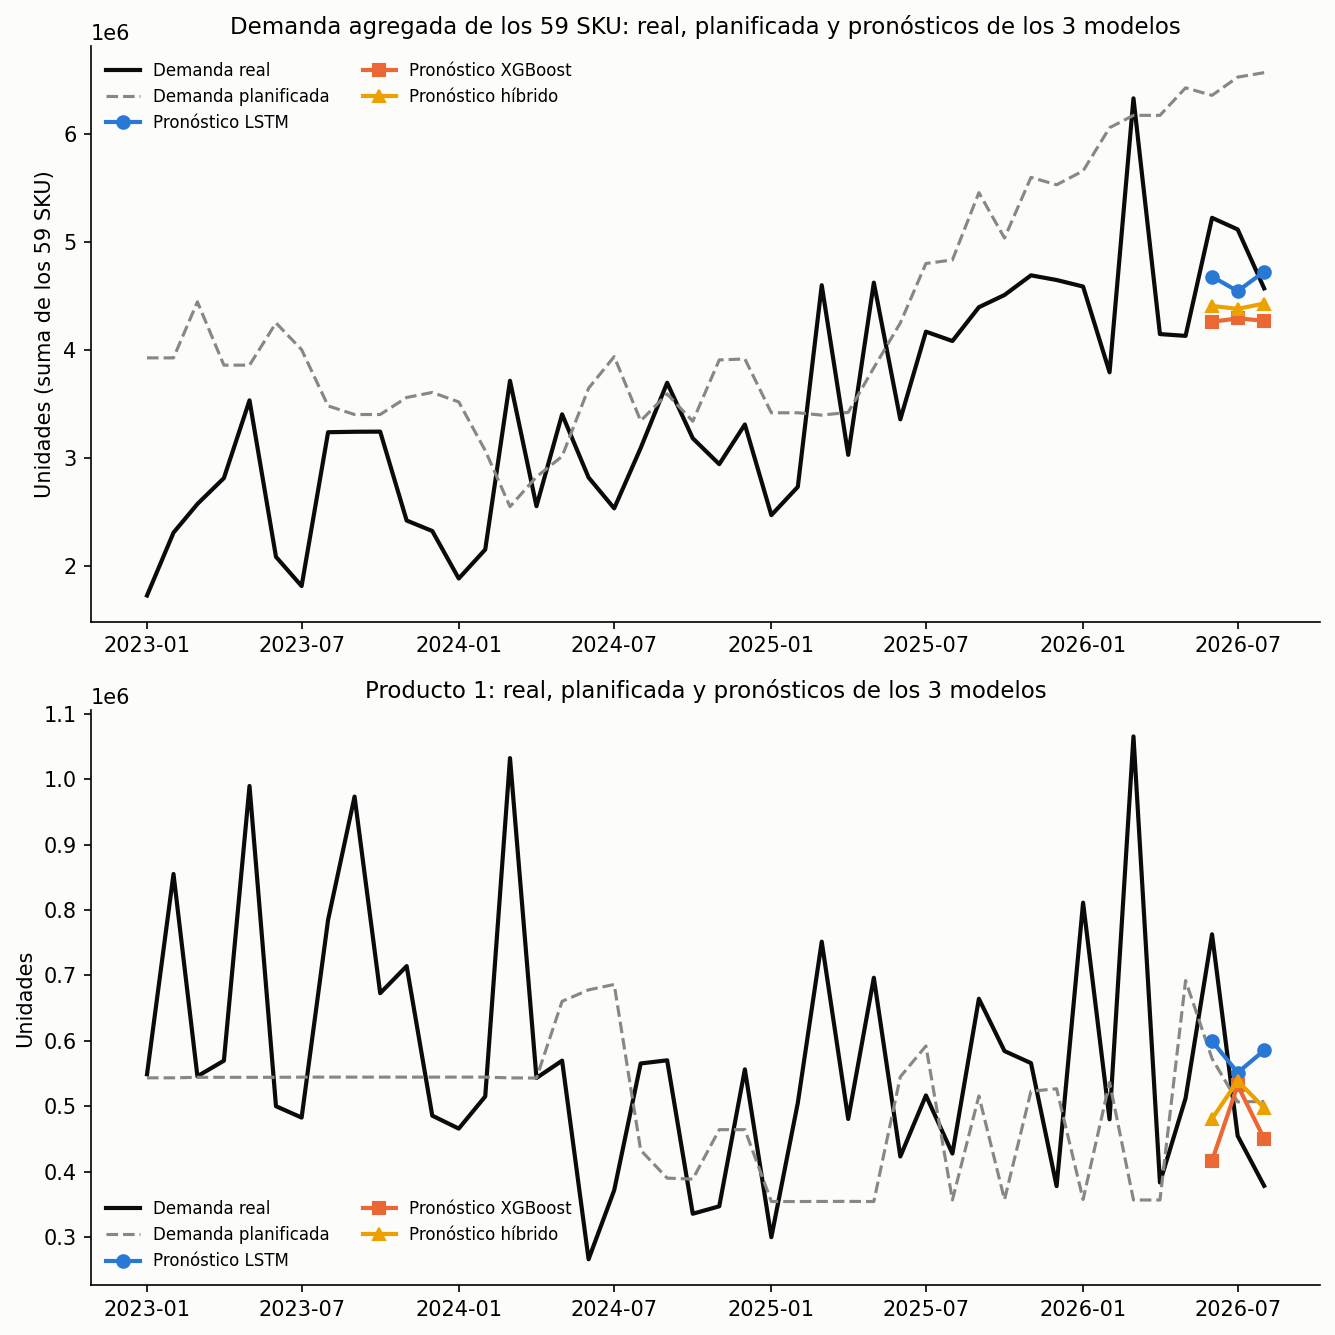

In [ ]:
import matplotlib.pyplot as plt

# --- Datos agregados (59 SKU) con las predicciones de los 3 modelos ---
agg = consolidado.groupby('anio_mes').agg(
    demanda_planificada=('demanda_planificada', 'sum'),
    demanda_real=('demanda_real', 'sum')
).reset_index()
agg['mes_dt'] = agg['anio_mes'].dt.to_timestamp()

pred_agg = comparacion_test.groupby('anio_mes').agg(
    lstm_pred=('lstm_pred', 'sum'),
    xgb_pred=('xgb_pred', 'sum'),
    hibrido_pred=('hibrido_pred', 'sum'),
).reset_index()
pred_agg['mes_dt'] = pred_agg['anio_mes'].dt.to_timestamp()

# --- SKU con más historia (el mismo de la Figura 5) ---
sku_ejemplo = consolidado[consolidado.tiene_dato_real].groupby('sku').size().sort_values(ascending=False).index[0]
ej = consolidado[consolidado.sku == sku_ejemplo].sort_values('anio_mes').copy()
ej['mes_dt'] = ej['anio_mes'].dt.to_timestamp()

pred_sku = comparacion_test[comparacion_test['sku'] == sku_ejemplo].sort_values('anio_mes').copy()
pred_sku['mes_dt'] = pred_sku['anio_mes'].dt.to_timestamp()

print("SKU usado (el mismo de la Figura 5):", sku_ejemplo)
print(pred_sku[['anio_mes', 'demanda_real', 'xgb_pred', 'lstm_pred', 'hibrido_pred']].to_string(index=False))

# --- Figura de dos paneles ---
colores = {'real': '#0b0b0b', 'planificada': '#898781', 'LSTM': '#2a78d6', 'XGBoost': '#eb6834', 'Híbrido': '#eda100'}

fig, axes = plt.subplots(2, 1, figsize=(9, 9), dpi=150)
fig.patch.set_facecolor('#fcfcfb')

ax = axes[0]
ax.plot(agg['mes_dt'], agg['demanda_real'], color=colores['real'], linewidth=2, label='Demanda real')
ax.plot(agg['mes_dt'], agg['demanda_planificada'], color=colores['planificada'], linewidth=1.5, linestyle='--', label='Demanda planificada')
ax.plot(pred_agg['mes_dt'], pred_agg['lstm_pred'], color=colores['LSTM'], marker='o', markersize=6, linewidth=2, label='Pronóstico LSTM')
ax.plot(pred_agg['mes_dt'], pred_agg['xgb_pred'], color=colores['XGBoost'], marker='s', markersize=6, linewidth=2, label='Pronóstico XGBoost')
ax.plot(pred_agg['mes_dt'], pred_agg['hibrido_pred'], color=colores['Híbrido'], marker='^', markersize=6, linewidth=2, label='Pronóstico híbrido')
ax.set_title('Demanda agregada de los 59 SKU: real, planificada y pronósticos de los 3 modelos', fontsize=11)
ax.set_ylabel('Unidades (suma de los 59 SKU)')
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_facecolor('#fcfcfb')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.plot(ej['mes_dt'], ej['demanda_real'], color=colores['real'], linewidth=2, label='Demanda real')
ax.plot(ej['mes_dt'], ej['demanda_planificada'], color=colores['planificada'], linewidth=1.5, linestyle='--', label='Demanda planificada')
ax.plot(pred_sku['mes_dt'], pred_sku['lstm_pred'], color=colores['LSTM'], marker='o', markersize=6, linewidth=2, label='Pronóstico LSTM')
ax.plot(pred_sku['mes_dt'], pred_sku['xgb_pred'], color=colores['XGBoost'], marker='s', markersize=6, linewidth=2, label='Pronóstico XGBoost')
ax.plot(pred_sku['mes_dt'], pred_sku['hibrido_pred'], color=colores['Híbrido'], marker='^', markersize=6, linewidth=2, label='Pronóstico híbrido')
ax.set_title(f'{sku_ejemplo}: real, planificada y pronósticos de los 3 modelos', fontsize=11)
ax.set_ylabel('Unidades')
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_facecolor('#fcfcfb')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('figuras14_15_comparacion_pronosticos.png', dpi=150, facecolor='#fcfcfb', bbox_inches='tight')
plt.show()

## Figuras 16, 17 y 18

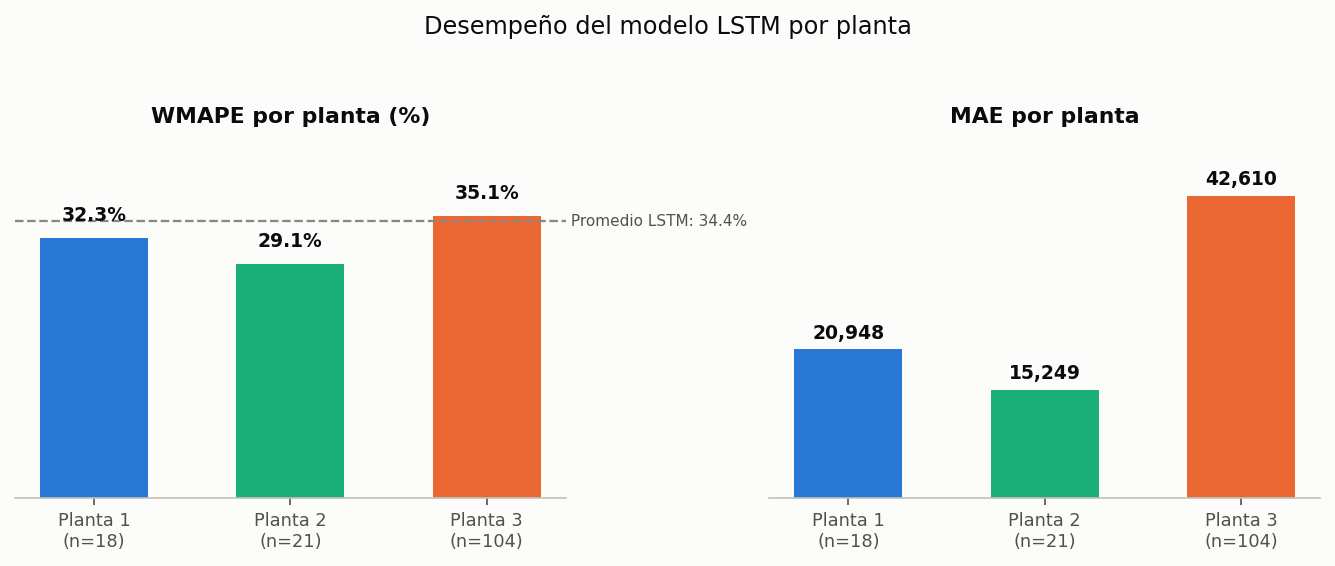

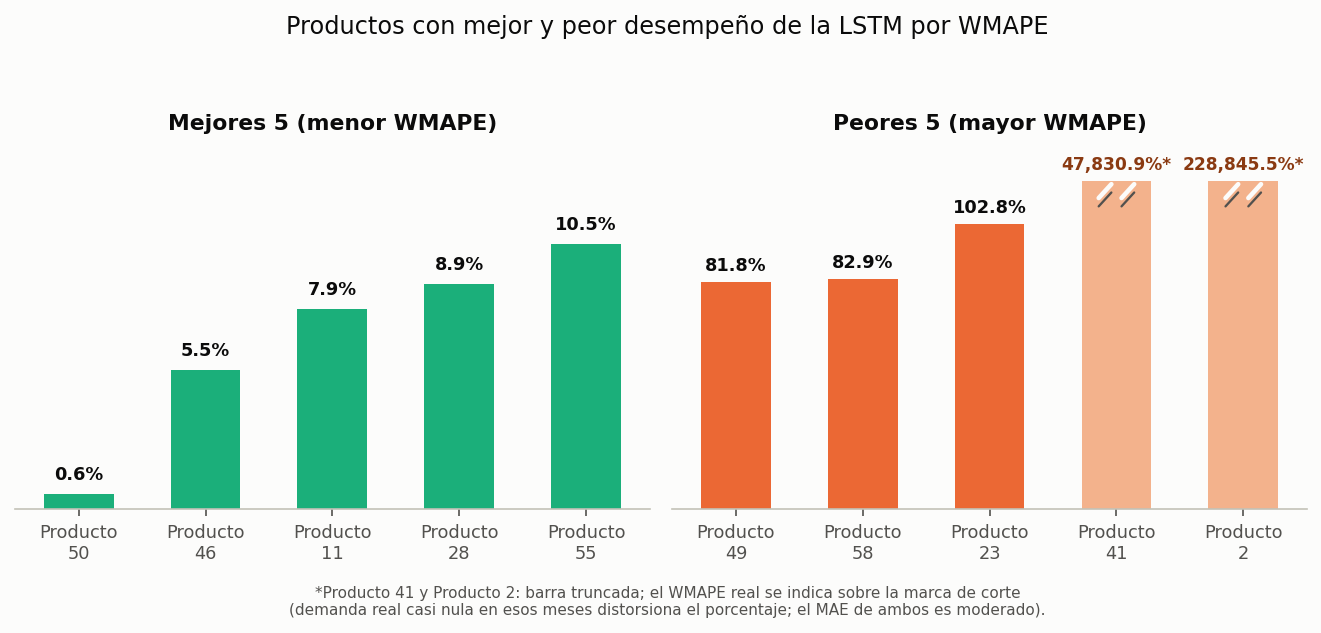

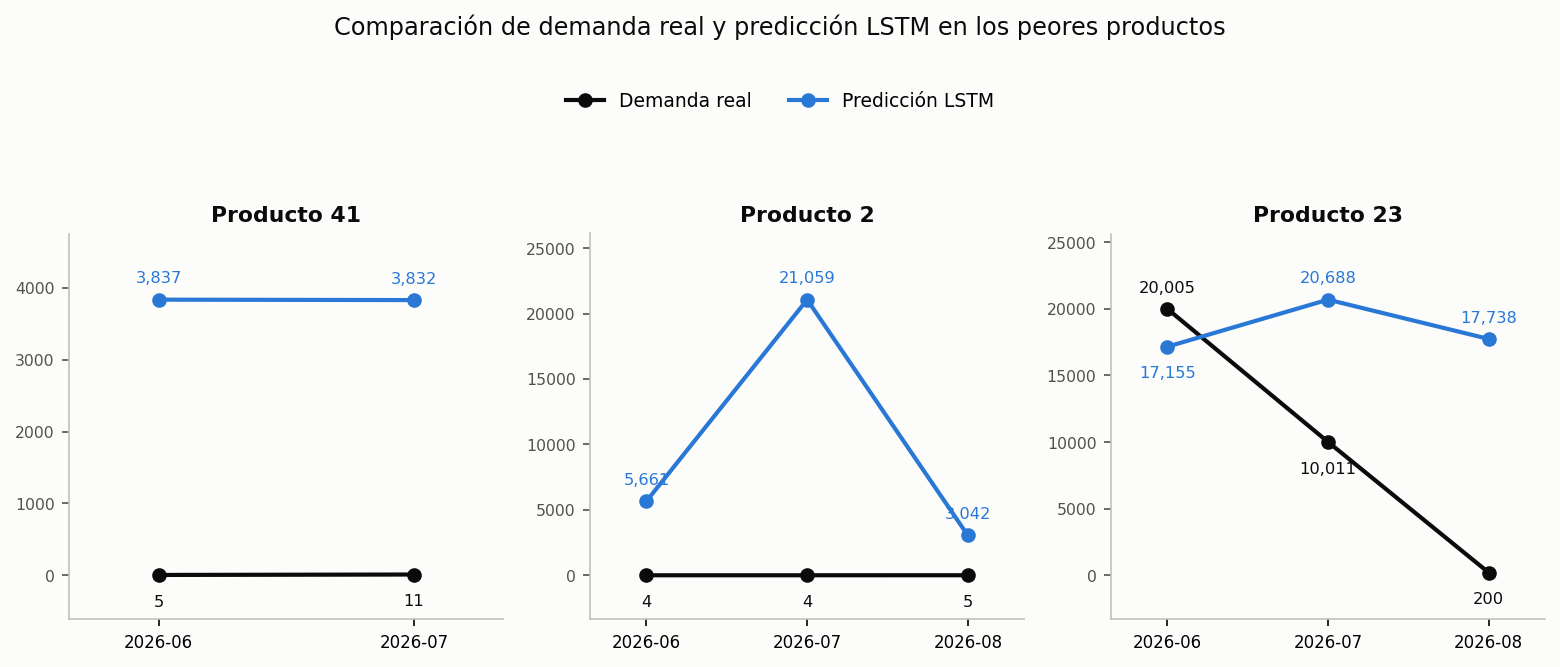

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from IPython.display import Image, display

BG = '#fcfcfb'; TXT = '#0b0b0b'; SPINE = '#c3c2b7'
C_PLANTA = {'Planta 1': '#2a78d6', 'Planta 2': '#1baf7a', 'Planta 3': '#eb6834'}
C_BEST = '#1baf7a'; C_WORST = '#eb6834'; C_WORST_CUT = '#f3b28c'

def style_ax(ax):
    ax.set_facecolor(BG)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color(SPINE)
    ax.get_yaxis().set_visible(False)
    ax.tick_params(axis='x', labelsize=8.5, colors='#52514e')

# --- Figura 16: WMAPE y MAE por planta ---
# Valores calculados a partir de los resultados de la evaluación por planta
por_planta = comp_seg.groupby('linea', observed=True).apply(lambda g: metricas_seg(g, 'lstm_pred'))
plantas = por_planta.index.tolist()
n_vals = por_planta['n'].astype(int).tolist()
mae_vals = por_planta['MAE'].tolist()
wmape_vals = por_planta['WMAPE_%'].tolist()
colors = [C_PLANTA[p] for p in plantas]
plantas_lbl = [f'{p}\n(n={n})' for p, n in zip(plantas, n_vals)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), dpi=150)
fig.patch.set_facecolor(BG)

ax = axes[0]
bars = ax.bar(plantas_lbl, wmape_vals, color=colors, width=0.55)
for bar, v in zip(bars, wmape_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.6, f'{v:.1f}%',
            ha='center', va='bottom', fontsize=9, color=TXT, fontweight='bold')
avg = lstm_metrics['WMAPE_%']
ax.axhline(avg, color='#898781', linestyle='--', linewidth=1.1)
trans = blended_transform_factory(ax.transAxes, ax.transData)
ax.text(1.0, avg, f' Promedio LSTM: {avg}%', transform=trans, fontsize=7.3,
        color='#52514e', ha='left', va='center', clip_on=False)
ax.set_title('WMAPE por planta (%)', fontsize=10.5, color=TXT, fontweight='bold')
ax.set_ylim(0, max(wmape_vals)+10); style_ax(ax)

ax = axes[1]
bars = ax.bar(plantas_lbl, mae_vals, color=colors, width=0.55)
for bar, v in zip(bars, mae_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+900, f'{v:,.0f}',
            ha='center', va='bottom', fontsize=9, color=TXT, fontweight='bold')
ax.set_title('MAE por planta', fontsize=10.5, color=TXT, fontweight='bold')
ax.set_ylim(0, max(mae_vals)*1.2); style_ax(ax)

fig.suptitle('Desempeño del modelo LSTM por planta', fontsize=11.5, color=TXT)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('figura16_lstm_por_planta.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.close()
display(Image('figura16_lstm_por_planta.png'))

# --- Figura 17: Mejores/Peores 5 productos por WMAPE (con eje truncado) ---
# Mejores y peores 5 productos calculados a partir de por_sku
mejores, peores = por_sku.head(5), por_sku.tail(5)
mejores_prod = [p.replace(' ', '\n') for p in mejores.index]
mejores_wmape = mejores['WMAPE_%'].tolist()
peores_prod = [p.replace(' ', '\n') for p in peores.index]
peores_wmape_real = peores['WMAPE_%'].tolist()
CAP = 118
peores_wmape_plot = [min(v, CAP) for v in peores_wmape_real]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.0), dpi=150)
fig.patch.set_facecolor(BG)

ax = axes[0]
bars = ax.bar(mejores_prod, mejores_wmape, color=C_BEST, width=0.55)
for bar, v in zip(bars, mejores_wmape):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4, f'{v:.1f}%',
            ha='center', va='bottom', fontsize=8.5, color=TXT, fontweight='bold')
ax.set_title('Mejores 5 (menor WMAPE)', fontsize=10.5, color=TXT, fontweight='bold')
ax.set_ylim(0, max(mejores_wmape)+4); style_ax(ax)

ax = axes[1]
bar_colors = [C_WORST if v <= CAP else C_WORST_CUT for v in peores_wmape_real]
bars = ax.bar(peores_prod, peores_wmape_plot, color=bar_colors, width=0.55)
for bar, v_real, v_plot in zip(bars, peores_wmape_real, peores_wmape_plot):
    x = bar.get_x() + bar.get_width()/2
    if v_real <= CAP:
        ax.text(x, v_plot+2.5, f'{v_real:.1f}%', ha='center', va='bottom',
                fontsize=8.5, color=TXT, fontweight='bold')
    else:
        for dx in (-0.09, 0.09):
            ax.plot([x+dx-0.05, x+dx+0.05], [CAP-6, CAP-1], color=BG, linewidth=2.2, solid_capstyle='round', zorder=5)
            ax.plot([x+dx-0.05, x+dx+0.05], [CAP-9, CAP-4], color='#52514e', linewidth=1.1, solid_capstyle='round', zorder=6)
        ax.text(x, CAP+2.5, f'{v_real:,.1f}%*', ha='center', va='bottom',
                fontsize=8.2, color='#8a3a12', fontweight='bold')
ax.set_title('Peores 5 (mayor WMAPE)', fontsize=10.5, color=TXT, fontweight='bold')
ax.set_ylim(0, CAP+14); style_ax(ax)

fig.suptitle('Productos con mejor y peor desempeño de la LSTM por WMAPE', fontsize=11.5, color=TXT)
fig.text(0.5, -0.02,
    '*Producto 41 y Producto 2: barra truncada; el WMAPE real se indica sobre la marca de corte\n'
    '(demanda real casi nula en esos meses distorsiona el porcentaje; el MAE de ambos es moderado).',
    ha='center', fontsize=7.3, color='#52514e')
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.savefig('figura17_mejores_peores_productos.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.close()
display(Image('figura17_mejores_peores_productos.png'))

# --- Figura 18: Demanda real vs. predicción LSTM, peores productos ---
C_REAL = '#0b0b0b'; C_LSTM = '#2a78d6'
PEORES = ['Producto 41', 'Producto 2', 'Producto 23']
sub = comparacion_test[comparacion_test['sku'].isin(PEORES)].sort_values('anio_mes')
data = {p: {'meses': sub.loc[sub['sku'] == p, 'anio_mes'].astype(str).tolist(),
            'real':  sub.loc[sub['sku'] == p, 'demanda_real'].tolist(),
            'pred':  sub.loc[sub['sku'] == p, 'lstm_pred'].round(2).tolist()}
        for p in PEORES}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.0), dpi=150)
fig.patch.set_facecolor(BG)
for ax, (prod, d) in zip(axes, data.items()):
    x = list(range(len(d['meses'])))
    ax.plot(x, d['real'], color=C_REAL, marker='o', markersize=6, linewidth=2, label='Demanda real', zorder=3)
    ax.plot(x, d['pred'], color=C_LSTM, marker='o', markersize=6, linewidth=2, label='Predicción LSTM', zorder=3)
    ymax = max(max(d['real']), max(d['pred']))
    for xi, (rv, pv) in enumerate(zip(d['real'], d['pred'])):
        r_dy, p_dy = (-15, 8) if rv <= pv else (8, -15)
        ax.annotate(f'{rv:,.0f}', (xi, rv), textcoords="offset points", xytext=(0, r_dy), ha='center', fontsize=7.8, color=C_REAL, zorder=4)
        ax.annotate(f'{pv:,.0f}', (xi, pv), textcoords="offset points", xytext=(0, p_dy), ha='center', fontsize=7.8, color=C_LSTM, zorder=4)
    ax.set_xticks(x); ax.set_xticklabels(d['meses'], fontsize=8); ax.set_xlim(-0.35, len(x)-0.65)
    ax.set_title(prod, fontsize=10.5, color=TXT, fontweight='bold')
    ax.set_facecolor(BG); ax.spines[['top','right']].set_visible(False)
    ax.spines['left'].set_color(SPINE); ax.spines['bottom'].set_color(SPINE)
    ax.tick_params(axis='y', labelsize=7.5, colors='#52514e')
    ax.set_ylim(-ymax*0.16, ymax*1.24)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=9, ncol=2)
fig.suptitle('Comparación de demanda real y predicción LSTM en los peores productos', fontsize=11.5, color=TXT, y=1.1)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('figura18_peores_productos.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.close()
display(Image('figura18_peores_productos.png'))